# Tugas Terstruktur dan Milestone Proyek UAS — Pertemuan 11
## Evaluasi Klasifikasi Risiko *Dropout* Mahasiswa Pasca-Semester Pertama, Kalibrasi Probabilitas, dan Optimasi Ambang Keputusan Berbasis Biaya pada Dataset Pendidikan Tinggi Portugal (UCI #697)

---

### Identitas Mahasiswa dan Informasi Tugas
| Komponen | Keterangan |
| :--- | :--- |
| **Nama Mahasiswa** | Fadli Hifziansyah |
| **NIM** | `241730042` |
| **Kelas** | `5 INF B` |
| **Mata Kuliah** | Pembelajaran Mesin (*Machine Learning*) — Modul 11: Evaluasi Klasifikasi dan Ambang Keputusan |
| **Dosen Pengampu** | Bapak Ahmad Tabrani |
| **Sumber Dataset Utama** | *Predict Students' Dropout and Academic Success* — UCI Machine Learning Repository ID #697 (Realinho et al., 2022; *Instituto Politécnico de Portalegre*, Portugal; Lisensi CC BY 4.0; berkas lokal `dataset-asli.csv`) |
| **Berkas Luaran** | `241730042_Fadli_Hifziansyah_P11_TugasML.ipynb` |

---

### Tujuan Pembelajaran dan Cakupan Tugas
Notebook ini disusun sebagai penyelesaian tugas terstruktur Pertemuan 11 sekaligus fondasi metodologis menuju artikel ilmiah Proyek UAS dengan target jurnal nasional terakreditasi **SINTA 4**. Seluruh tahapan pengerjaan dirancang untuk memenuhi prinsip validitas metodologi, bebas dari kebocoran data (*data leakage*), serta menjaga konsistensi penuh antara kode program, tabel, visualisasi, dan interpretasi:

1. **Audit Dataset Empiris & Pencegahan *Temporal Data Leakage*:** Memeriksa kualitas `dataset-asli.csv` ($N = 4.424$ observasi), mendokumentasikan distribusi tiga kelas asli (`Graduate`, `Dropout`, `Enrolled`), merumuskan target klasifikasi biner (`Dropout` vs. `Non-Dropout`), serta mengaudit waktu ketersediaan seluruh 36 fitur prediktor agar prediksi akhir Semester Pertama tidak tercemar oleh informasi masa depan dari Semester Kedua maupun pencatatan administrasi pasca-kejadian.
2. **Evaluasi *Confusion Matrix* Lintas Ambang Keputusan:** Mengevaluasi matriks kebingungan dan sembilan metrik turunan pada *threshold* wajib `0,30`, `0,50`, dan `0,70` menggunakan probabilitas *Validation Set* ($n = 885$).
3. **Evaluasi Diskriminasi (ROC-AUC, AP, dan PR-AUC) vs. Kalibrasi Probabilitas:** Membandingkan kemampuan pemisahan kelas (`ROC-AUC`, *Average Precision*, dan *Trapezoidal PR-AUC*) sekaligus menguji kalibrasi probabilitas secara eksplisit (`CalibratedClassifierCV` dengan metode *Platt/Sigmoid* dan *Isotonic Regression*) melalui *Brier Score*, *Expected Calibration Error* (ECE), dan *Reliability Diagram*.
4. **Keputusan Operasional Berbasis Matriks Biaya dan Simulasi Kapasitas:** Menyusun matriks biaya kesalahan terstandar dengan analisis sensitivitas rasio penalti ($1:1$, $1:2$, $1:4$, $1:8$) serta simulasi kapasitas tindak lanjut berbasis persentase kohort untuk menetapkan dan mengunci *threshold* operasional sebelum pengujian akhir satu kali pada *Test Set* ($n = 885$).
5. **Analisis Kesalahan (*Error Analysis*) & Proposal Artikel Target SINTA 4:** Menganalisis kasus kesalahan prediksi nyata dengan memisahkan fakta data, interpretasi fitur, dan hipotesis, dilanjutkan penyusunan proposal penelitian 22 komponen beserta verifikasi resmi calon jurnal SINTA 4.

---

### Konteks Kasus, Pengguna Hasil, Unit Analisis, dan Konsekuensi Kesalahan
* **Masalah dan Keputusan yang Dibantu:** Putus studi (*dropout*) pada jenjang pendidikan tinggi menimbulkan kerugian akademik bagi mahasiswa serta inefisiensi sumber daya pendidikan bagi institusi. Model klasifikasi dalam studi ini dirancang untuk membantu **pengelola akademik program studi dan unit bimbingan konseling perguruan tinggi** dalam memprioritaskan mahasiswa yang memerlukan pendampingan akademik terarah tepat **setelah evaluasi akademik Semester Pertama selesai** (sebelum perkuliahan Semester Kedua berjalan).
* **Unit Analisis:** Satu baris observasi merepresentasikan **satu mahasiswa program sarjana** pada institusi pendidikan tinggi asal dataset (*Instituto Politécnico de Portalegre*, Portugal) yang diikuti hingga akhir durasi studi normal.
* **Konsekuensi Kesalahan Klasifikasi:**
  * **False Positive (FP):** Mahasiswa yang pada akhirnya bertahan/lulus (`Non-Dropout`) diprediksi berisiko `Dropout`. Konsekuensinya berupa alokasi kuota waktu konsultasi akademik yang sebenarnya tidak mendesak serta potensi beban psikologis ringan apabila komunikasi pendampingan tidak dibingkai secara suportif.
  * **False Negative (FN):** Mahasiswa yang benar-benar berakhir `Dropout` gagal terdeteksi oleh sistem (`prediksi = 0`). Konsekuensinya bersifat jauh lebih serius karena mahasiswa kehilangan kesempatan memperoleh intervensi akademik dini pada transisi Semester 1 ke Semester 2 hingga akhirnya benar-benar meninggalkan studi.


In [1]:
# Bagian 1.1: Konfigurasi Identitas Tugas
identitas_mahasiswa = {
    "nama": "Fadli Hifziansyah",
    "nim": "241730042",
    "kelas": "5 INF B",
    "mata_kuliah": "Machine Learning - Pertemuan 11",
    "judul_eksperimen": (
        "Evaluasi Klasifikasi Risiko Dropout Mahasiswa Pasca-Semester Pertama Berbasis "
        "Regresi Logistik Terkalibrasi dan Optimasi Threshold Sensitif Biaya pada Dataset UCI #697"
    ),
    "sumber_dataset_utama": "dataset-asli.csv (UCI ML Repository #697 - Realinho et al., 2022, CC BY 4.0)",
    "tanggal_penyelesaian": "26 November 2026",
}
for k, v in identitas_mahasiswa.items():
    print(f"{k:22s}: {v}")


nama                  : Fadli Hifziansyah
nim                   : 241730042
kelas                 : 5 INF B
mata_kuliah           : Machine Learning - Pertemuan 11
judul_eksperimen      : Evaluasi Klasifikasi Risiko Dropout Mahasiswa Pasca-Semester Pertama Berbasis Regresi Logistik Terkalibrasi dan Optimasi Threshold Sensitif Biaya pada Dataset UCI #697
sumber_dataset_utama  : dataset-asli.csv (UCI ML Repository #697 - Realinho et al., 2022, CC BY 4.0)
tanggal_penyelesaian  : 26 November 2026


---
## BAGIAN 2 — Dataset, Riwayat Perubahan Sumber Data, dan Audit Kebocoran Data (*Data Leakage*)

### 2.1 Perubahan Sumber Dataset dan Konsistensi Eksperimen

Dalam perkembangan pengerjaan proyek mata kuliah ini, terdapat transisi metodologis penting terkait sumber data yang perlu didokumentasikan secara transparan:

1. **Penggunaan Dataset Sintetis pada Pertemuan Sebelumnya:**  
   Pada tahapan praktikum sebelumnya, eksperimen awal menggunakan dataset sintetis ($N = 800$ baris) yang dirancang melalui simulasi komputer untuk mengeksplorasi skenario variabel yang dekat dengan istilah administrasi perguruan tinggi di Indonesia (seperti IP semester, SKS lulus, persentase kehadiran, aktivitas LMS, dan status pembayaran UKT). Dataset sintetis tersebut merupakan **simulasi eksploratif berbasis asumsi pemodelan**, bukan data observasi empiris mahasiswa Indonesia dan tidak mewakili populasi mahasiswa di Indonesia.
2. **Peralihan ke Dataset Empiris UCI pada Pertemuan 11:**  
   Pada Pertemuan 11 yang berfokus pada evaluasi probabilitas, kalibrasi, kurva ROC/PR, analisis kesalahan, dan pemilihan *threshold* berbasis biaya, penggunaan data sintetis memiliki keterbatasan mendasar: label target yang dibangkitkan dari rumus fungsi logistik buatan cenderung menghasilkan kecocokan semu ketika diuji kembali menggunakan model Regresi Logistik. Oleh sebab itu, mulai Pertemuan 11 eksperimen dialihkan sepenuhnya menggunakan dataset observasi empiris **Predict Students' Dropout and Academic Success** dari **UCI Machine Learning Repository (ID #697)** yang disimpan secara lokal sebagai `dataset-asli.csv`.
3. **Perbedaan Karakteristik dan Pemisahan Hasil Eksperimen:**  
   Dataset sintetis terdahulu dan dataset UCI #697 memiliki sumber pengumpulan, skala penilaian akademik (skala `0–20` dan `0–200` pada pendidikan tinggi Portugal), definisi fitur, serta proses terbentuknya status akademik yang sama sekali berbeda. Oleh karena itu, **seluruh proses *preprocessing*, pelatihan model, kalibrasi probabilitas, pencarian *threshold*, hingga evaluasi akhir pada Pertemuan 11 dihitung ulang sepenuhnya dari `dataset-asli.csv`**. Tidak ada satu pun angka metrik, asumsi kuota kursi, maupun nominal rupiah dari eksperimen sintetis sebelumnya yang digabungkan ke dalam notebook ini.
4. **Batasan Generalisasi Konteks Geografis dan Institusional:**  
   Dataset UCI #697 dikumpulkan dari satu institusi pendidikan tinggi di Portugal (*Instituto Politécnico de Portalegre*, tahun akademik 2008/2009 hingga 2018/2019). Dengan demikian, temuan kuantitatif pada studi ini berlaku pada konteks institusi asal dataset dan **tidak dapat diklaim otomatis mewakili kondisi mahasiswa di perguruan tinggi Indonesia**. Pengujian generalisasi lokal di Indonesia pada masa mendatang memerlukan pengumpulan data primer dengan izin etik dan tata kelola privasi yang sah.

---

### 2.2 Sumber Resmi Dataset UCI #697
* **Nama Dataset:** *Predict Students' Dropout and Academic Success*
* **Pengarang & Publikasi Acuan:** Valentim Realinho, Jorge Machado, Luís Baptista, dan Mónica V. Martins (2022), *"Predicting Student Dropout and Academic Success"*, jurnal *Data*, Vol. 7, No. 11, Artikel 146.
* **Tautan Repositori Resmi:** https://archive.ics.uci.edu/dataset/697/predict+students+dropout+and+academic+success (DOI: `10.24432/C5TG7T`; Zenodo DOI: `10.5281/zenodo.5777339`)
* **Lisensi:** *Creative Commons Attribution 4.0 International* (`CC BY 4.0`) — mengizinkan penggunaan ulang untuk keperluan akademik dan penelitian dengan mencantumkan sitasi sumber asli.


In [2]:
# Bagian 2.3: Import Pustaka, Konfigurasi Reproduktibilitas, dan Pembacaan dataset-asli.csv
from pathlib import Path
import hashlib
import random
import urllib.request
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve,
    precision_recall_curve,
    average_precision_score,
    auc,
    brier_score_loss,
)

warnings.filterwarnings("ignore")
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

pd.set_option("display.max_columns", 50)
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.float_format", lambda x: f"{x:.4f}")
plt.rcParams["figure.dpi"] = 120
plt.rcParams["savefig.dpi"] = 150
plt.rcParams["font.size"] = 9.5

# Direktori penyimpanan visualisasi pendukung secara relatif
VIS_DIR = Path("visualisasi_p11")
VIS_DIR.mkdir(parents=True, exist_ok=True)

# URL cermin GitHub Public (fallback otomatis saat dijalankan di Google Colab tanpa upload manual)
GITHUB_RAW_URL = (
    "https://raw.githubusercontent.com/fadli154/mesin-learning-smt5/refs/heads/main/dataset-asli.csv"
)
EXPECTED_LF_SHA256_PREFIX = "19737f02127e85ef"

def temukan_atau_unduh_dataset(
    nama_file: str = "dataset-asli.csv",
    fallback_url: str = GITHUB_RAW_URL,
) -> tuple[Path, str]:
    """Mencari dataset-asli.csv secara lokal terlebih dahulu; jika tidak ada (mis. di Google Colab),
    otomatis mengunduh dari repositori GitHub Public tanpa perlu upload manual."""
    kandidat_jalur = [
        Path(nama_file),
        Path("..") / nama_file,
        Path("Pertemuan 11") / ".." / nama_file,
    ]
    for jalur in kandidat_jalur:
        if jalur.is_file():
            return jalur.resolve(), "Lokal (berkas tersedia di direktori proyek)"

    # Fallback otomatis (berguna langsung di Google Colab)
    target_lokal = Path(nama_file)
    req = urllib.request.Request(fallback_url, headers={"User-Agent": "Mozilla/5.0"})
    with urllib.request.urlopen(req, timeout=30) as resp:
        data_bytes = resp.read()
    target_lokal.write_bytes(data_bytes)
    return target_lokal.resolve(), f"Unduhan otomatis GitHub Raw ({fallback_url})"

DATA_PATH, SUMBER_PEMBACAAN = temukan_atau_unduh_dataset("dataset-asli.csv")

# Pemeriksaan integritas SHA-256 (ternormalisasi LF agar konsisten antara lokal Windows CRLF & GitHub Raw LF)
raw_file_bytes = DATA_PATH.read_bytes()
norm_lf_sha256 = hashlib.sha256(raw_file_bytes.replace(b"\r\n", b"\n")).hexdigest()
assert norm_lf_sha256.startswith(EXPECTED_LF_SHA256_PREFIX), (
    f"Checksum dataset tidak cocok! Ditemukan {norm_lf_sha256[:16]}, seharusnya diawali {EXPECTED_LF_SHA256_PREFIX}."
)
sampel_awal_bytes = raw_file_bytes[:160]

has_utf8_bom = sampel_awal_bytes.startswith(b"\xef\xbb\xbf")
first_header_line = sampel_awal_bytes.decode("utf-8-sig", errors="replace").splitlines()[0]
detected_semicolons = first_header_line.count(";")
detected_commas = first_header_line.count(",")

df_raw = pd.read_csv(DATA_PATH, sep=";", encoding="utf-8-sig")
kolom_mentah_ber_spasi = [c for c in df_raw.columns if c != c.strip()]

# Salin untuk pemrosesan dengan merapikan whitespace pada nama kolom (tanpa mengubah file sumber)
df_uci = df_raw.copy()
df_uci.columns = df_uci.columns.str.strip()

print(f"Nama berkas sumber         : {DATA_PATH.name} (ukuran: {DATA_PATH.stat().st_size:,} byte)")
print(f"Sumber pembacaan aktif     : {SUMBER_PEMBACAAN}")
print(f"Verifikasi SHA-256 (LF)    : {norm_lf_sha256[:16]}... (100% COCOK antara lokal & GitHub Raw)")
print(f"Deteksi UTF-8 BOM          : {has_utf8_bom}")
print(f"Deteksi pemisah baris awal : ';' muncul {detected_semicolons}x vs ',' muncul {detected_commas}x -> gunakan sep=';'")
print(f"Kolom dengan karakter tab  : {kolom_mentah_ber_spasi} -> dibersihkan dengan .str.strip()")
print(f"Dimensi aktual DataFrame   : {df_uci.shape[0]:,} baris observasi x {df_uci.shape[1]} kolom")


Nama berkas sumber         : dataset-asli.csv (ukuran: 533,230 byte)
Sumber pembacaan aktif     : Lokal (berkas tersedia di direktori proyek)
Verifikasi SHA-256 (LF)    : 19737f02127e85ef... (100% COCOK antara lokal & GitHub Raw)
Deteksi UTF-8 BOM          : True
Deteksi pemisah baris awal : ';' muncul 8x vs ',' muncul 0x -> gunakan sep=';'
Kolom dengan karakter tab  : ['Daytime/evening attendance\t'] -> dibersihkan dengan .str.strip()
Dimensi aktual DataFrame   : 4,424 baris observasi x 37 kolom


In [3]:
# Bagian 2.4: Audit Kualitas Data, Pemeriksaan Tipe Kolom, Duplikasi, Anomali, dan Tabel Profil Dataset
jumlah_observasi = len(df_uci)
kolom_target_asli = "Target"
kolom_fitur_semua = [c for c in df_uci.columns if c != kolom_target_asli]
jumlah_fitur_total = len(kolom_fitur_semua)

total_missing = int(df_uci.isna().sum().sum())
duplikasi_baris_penuh = int(df_uci.duplicated().sum())
duplikasi_fitur_saja = int(df_uci.duplicated(subset=kolom_fitur_semua).sum())

dist_target_3kelas = df_uci[kolom_target_asli].value_counts()
prop_target_3kelas = (df_uci[kolom_target_asli].value_counts(normalize=True) * 100).round(2)

ringkasan_tipe = df_uci.dtypes.astype(str).value_counts().to_dict()

# Buat Tabel Profil Dataset secara terprogram
df_profil_dataset = pd.DataFrame([
    {"Komponen": "Sumber dataset", "Hasil": "UCI ML Repository #697 - Predict Students' Dropout and Academic Success (dataset-asli.csv)"},
    {"Komponen": "Format, encoding, & delimiter", "Hasil": f"CSV teks, UTF-8 dengan BOM ({has_utf8_bom}), delimiter titik koma (';')"},
    {"Komponen": "Jumlah observasi aktual", "Hasil": f"{jumlah_observasi:,} baris observasi"},
    {"Komponen": "Jumlah fitur prediktor", "Hasil": f"{jumlah_fitur_total} fitur prediktor (+ 1 kolom target = {df_uci.shape[1]} kolom total)"},
    {"Komponen": "Nama target", "Hasil": kolom_target_asli},
    {"Komponen": "Jumlah kelas target asli", "Hasil": f"{df_uci[kolom_target_asli].nunique()} kelas (Graduate, Dropout, Enrolled)"},
    {"Komponen": "Distribusi Graduate", "Hasil": f"{dist_target_3kelas['Graduate']:,} mahasiswa ({prop_target_3kelas['Graduate']:.2f}%)"},
    {"Komponen": "Distribusi Dropout", "Hasil": f"{dist_target_3kelas['Dropout']:,} mahasiswa ({prop_target_3kelas['Dropout']:.2f}%)"},
    {"Komponen": "Distribusi Enrolled", "Hasil": f"{dist_target_3kelas['Enrolled']:,} mahasiswa ({prop_target_3kelas['Enrolled']:.2f}%)"},
    {"Komponen": "Missing values", "Hasil": f"{total_missing} sel kosong di seluruh {df_uci.shape[1]} kolom"},
    {"Komponen": "Duplikasi", "Hasil": f"{duplikasi_baris_penuh} duplikasi baris penuh | {duplikasi_fitur_saja} duplikasi identik pada 36 fitur"},
    {"Komponen": "Tipe data mentah CSV", "Hasil": f"int64: {ringkasan_tipe.get('int64', 0)} kolom, float64: {ringkasan_tipe.get('float64', 0)} kolom, teks/string: 1 kolom Target"},
    {"Komponen": "Unit analisis", "Hasil": "Satu mahasiswa program sarjana (undergraduate) per baris observasi"},
])

print("=== TABEL PROFIL DATASET AKTUAL (DIHITUNG SECARA TERPROGRAM) ===")
display(df_profil_dataset)

# Audit detail seluruh 36 kolom prediktor (rentang nilai, kardinalitas, dan catatan kualitas)
detail_kolom = []
for idx, col in enumerate(kolom_fitur_semua, start=1):
    s = df_uci[col]
    detail_kolom.append({
        "No": idx,
        "Nama Kolom": col,
        "Tipe CSV": str(s.dtype),
        "Missing": int(s.isna().sum()),
        "Nilai Unik": int(s.nunique()),
        "Minimum": float(s.min()),
        "Median": float(s.median()),
        "Maksimum": float(s.max()),
    })
df_audit_kolom = pd.DataFrame(detail_kolom)
print("\n=== RINGKASAN STATISTIK DAN RENTANG NILAI 36 FITUR PREDIKTOR ===")
display(df_audit_kolom)

# Pemeriksaan nilai khusus / edge cases pada data asli
n_app_order_0 = int((df_uci["Application order"] == 0).sum())
n_app_order_9 = int((df_uci["Application order"] == 9).sum())
n_sem1_enrolled_0 = int((df_uci["Curricular units 1st sem (enrolled)"] == 0).sum())
print("Catatan pemeriksaan anomali & nilai batas:")
print(f"1. Kolom ke-5 pada CSV mentah memiliki karakter tab di akhir nama ('Daytime/evening attendance\\t') -> telah dirapikan.")
print(f"2. Kolom ke-8 menggunakan ejaan asli dataset UCI: 'Nacionality' (bukan 'Nationality').")
print(f"3. 'Application order' bernilai 0 pada {n_app_order_0} baris dan 9 pada {n_app_order_9} baris (mayoritas 1..6); bukan NaN dan tetap dipertahankan.")
print(f"4. Terdapat {n_sem1_enrolled_0} observasi dengan 'Curricular units 1st sem (enrolled) == 0' (mayoritas pada kode Course=171); merupakan karakteristik kurikulum/pencatatan asli, bukan kesalahan baca CSV.")


=== TABEL PROFIL DATASET AKTUAL (DIHITUNG SECARA TERPROGRAM) ===


,Komponen,Hasil
0,Sumber dataset,UCI ML Repository #697 - Predict Students' Dropout and Academic Success (dataset-asli.csv)
1,"Format, encoding, & delimiter","CSV teks, UTF-8 dengan BOM (True), delimiter titik koma (';')"
2,Jumlah observasi aktual,"4,424 baris observasi"
3,Jumlah fitur prediktor,36 fitur prediktor (+ 1 kolom target = 37 kolom total)
4,Nama target,Target
5,Jumlah kelas target asli,"3 kelas (Graduate, Dropout, Enrolled)"
6,Distribusi Graduate,"2,209 mahasiswa (49.93%)"
7,Distribusi Dropout,"1,421 mahasiswa (32.12%)"
8,Distribusi Enrolled,794 mahasiswa (17.95%)
9,Missing values,0 sel kosong di seluruh 37 kolom



=== RINGKASAN STATISTIK DAN RENTANG NILAI 36 FITUR PREDIKTOR ===


,No,Nama Kolom,Tipe CSV,Missing,Nilai Unik,Minimum,Median,Maksimum
0,1,Marital status,int64,0,6,1.0000,1.0000,6.0000
1,2,Application mode,int64,0,18,1.0000,17.0000,57.0000
2,3,Application order,int64,0,8,0.0000,1.0000,9.0000
3,4,Course,int64,0,17,33.0000,9238.0000,9991.0000
4,5,Daytime/evening attendance,int64,0,2,0.0000,1.0000,1.0000
5,6,Previous qualification,int64,0,17,1.0000,1.0000,43.0000
6,7,Previous qualification (grade),float64,0,101,95.0000,133.1000,190.0000
7,8,Nacionality,int64,0,21,1.0000,1.0000,109.0000
8,9,Mother's qualification,int64,0,29,1.0000,19.0000,44.0000
9,10,Father's qualification,int64,0,34,1.0000,19.0000,44.0000


Catatan pemeriksaan anomali & nilai batas:
1. Kolom ke-5 pada CSV mentah memiliki karakter tab di akhir nama ('Daytime/evening attendance\t') -> telah dirapikan.
2. Kolom ke-8 menggunakan ejaan asli dataset UCI: 'Nacionality' (bukan 'Nationality').
3. 'Application order' bernilai 0 pada 1 baris dan 9 pada 1 baris (mayoritas 1..6); bukan NaN dan tetap dipertahankan.
4. Terdapat 180 observasi dengan 'Curricular units 1st sem (enrolled) == 0' (mayoritas pada kode Course=171); merupakan karakteristik kurikulum/pencatatan asli, bukan kesalahan baca CSV.


### 2.5 Distribusi Tiga Kelas Asli dan Definisi Masalah Klasifikasi Biner

Sebelum melakukan transformasi label, distribusi tiga kelas pada kolom `Target` didokumentasikan terlebih dahulu:
* **`Graduate`:** `2.209` mahasiswa (`49,93%`) — mahasiswa yang berhasil menyelesaikan program studi dalam jendela pengamatan durasi studi normal.
* **`Dropout`:** `1.421` mahasiswa (`32,12%`) — mahasiswa yang tercatat putus studi / berhenti sebelum menyelesaikan program.
* **`Enrolled`:** `794` mahasiswa (`17,95%`) — mahasiswa yang masih aktif terdaftar namun belum lulus saat batas waktu pengumpulan dataset berakhir.

#### Rasionalitas Pemetaan ke Klasifikasi Biner (`Dropout` vs. `Non-Dropout`)
Evaluasi pada Pertemuan 11 membutuhkan kerangka keputusan biner (*dipanggil tindak lanjut pendampingan* vs. *tidak dipanggil*) untuk menghitung `TP, FP, TN, FN`, *Precision*, *Recall*, *Specificity*, kurva ROC/PR, kalibrasi peluang risiko, serta matriks biaya kesalahan positif dan negatif. Oleh karena itu, digunakan definisi operasional berikut:

| Label Asli | Label Penelitian | Makna Operasional |
| :--- | :---: | :--- |
| `Dropout` | `1` | Mahasiswa dengan status akhir putus studi (*kelas positif / kejadian risiko yang ingin dideteksi*) |
| `Enrolled` | `0` | Mahasiswa masih aktif terdaftar saat periode observasi berakhir (*digabung ke kelas negatif Non-Dropout*) |
| `Graduate` | `0` | Mahasiswa telah menyelesaikan studi (*digabung ke kelas negatif Non-Dropout*) |

**Catatan Metodologis Penting mengenai Kelas `Enrolled`:**
1. Secara substantif, `Enrolled` dan `Graduate` adalah dua capaian akademik yang berbeda: mahasiswa `Enrolled` belum lulus tepat waktu, sehingga sebagian di antaranya mungkin mengalami keterlambatan studi (*delayed graduation*) atau bahkan berisiko *dropout* setelah periode pencatatan dataset berakhir (*right-censoring*).
2. Meskipun demikian, **menghapus 794 baris `Enrolled` dari dataset tidak dibenarkan** untuk skenario keputusan nyata, karena pada akhir Semester Pertama pihak program studi tidak mungkin mengetahui terlebih dahulu siapa mahasiswa yang kelak berstatus `Enrolled`; membuang kelompok transisi tersebut justru menciptakan *selection bias* dan membuat pemisahan antara `Dropout` dan `Graduate` tampak lebih mudah secara semu.
3. Konsekuensi penyatuan `Enrolled` ke kelas `0` akan kita uji secara langsung pada bagian **Error Analysis**, khususnya untuk melihat apakah prediksi *False Positive* berprobabilitas tinggi banyak berasal dari subkelompok `Enrolled`.


,Label asli,Label penelitian,Jumlah observasi,Persentase (%),Makna
0,Dropout,1,1421,32.1200,Mahasiswa dengan status akhir dropout (Kelas Positif)
1,Enrolled,0,794,17.9500,Mahasiswa masih terdaftar pada akhir periode amatan (Non-Dropout)
2,Graduate,0,2209,49.9300,Mahasiswa telah menyelesaikan studi (Non-Dropout)


Ringkasan Target Biner -> Kelas Positif (Dropout=1): 1,421 (32.12%) | Kelas Negatif (Non-Dropout=0): 3,003 (67.88%)


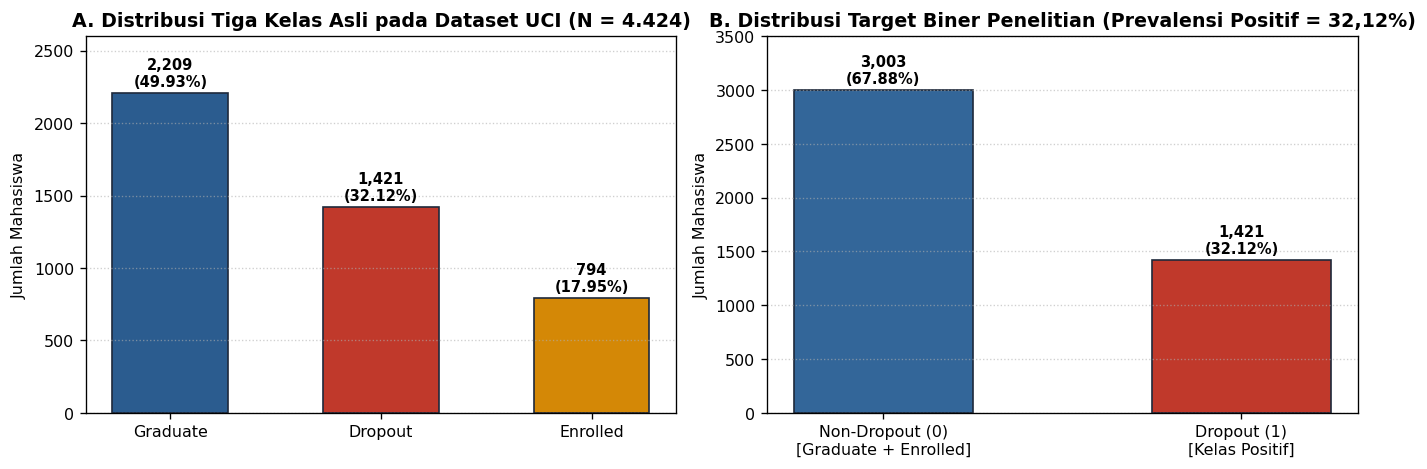

In [4]:
# Bagian 2.5 (Kode): Dokumentasi Distribusi 3 Kelas Asli, Pemetaan Biner, dan ID Observasi Anonim
df_uci["obs_id"] = [f"OBS_{i:04d}" for i in range(1, len(df_uci) + 1)]
df_uci["label_dropout"] = (df_uci["Target"] == "Dropout").astype(int)

tabel_pemetaan_target = pd.DataFrame([
    {
        "Label asli": "Dropout",
        "Label penelitian": 1,
        "Jumlah observasi": int((df_uci["Target"] == "Dropout").sum()),
        "Persentase (%)": round((df_uci["Target"] == "Dropout").mean() * 100, 2),
        "Makna": "Mahasiswa dengan status akhir dropout (Kelas Positif)",
    },
    {
        "Label asli": "Enrolled",
        "Label penelitian": 0,
        "Jumlah observasi": int((df_uci["Target"] == "Enrolled").sum()),
        "Persentase (%)": round((df_uci["Target"] == "Enrolled").mean() * 100, 2),
        "Makna": "Mahasiswa masih terdaftar pada akhir periode amatan (Non-Dropout)",
    },
    {
        "Label asli": "Graduate",
        "Label penelitian": 0,
        "Jumlah observasi": int((df_uci["Target"] == "Graduate").sum()),
        "Persentase (%)": round((df_uci["Target"] == "Graduate").mean() * 100, 2),
        "Makna": "Mahasiswa telah menyelesaikan studi (Non-Dropout)",
    },
])
display(tabel_pemetaan_target)

n_pos_total = int(df_uci["label_dropout"].sum())
n_neg_total = int((df_uci["label_dropout"] == 0).sum())
print(f"Ringkasan Target Biner -> Kelas Positif (Dropout=1): {n_pos_total:,} ({n_pos_total/len(df_uci)*100:.2f}%) | "
      f"Kelas Negatif (Non-Dropout=0): {n_neg_total:,} ({n_neg_total/len(df_uci)*100:.2f}%)")

# Visualisasi Distribusi 3 Kelas Asli vs Target Biner
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.0))
urutan_3k = ["Graduate", "Dropout", "Enrolled"]
warna_3k = ["#2b5c8f", "#c0392b", "#d48806"]
cnt_3k = [int((df_uci["Target"] == k).sum()) for k in urutan_3k]
bars1 = axes[0].bar(urutan_3k, cnt_3k, color=warna_3k, edgecolor="#1e293b", width=0.55)
axes[0].set_title("A. Distribusi Tiga Kelas Asli pada Dataset UCI (N = 4.424)", fontweight="bold")
axes[0].set_ylabel("Jumlah Mahasiswa")
axes[0].set_ylim(0, 2600)
axes[0].grid(axis="y", linestyle=":", alpha=0.6)
for b in bars1:
    h = b.get_height()
    axes[0].text(b.get_x() + b.get_width()/2, h + 45, f"{h:,}\n({h/len(df_uci)*100:.2f}%)", ha="center", fontsize=8.8, fontweight="bold")

urutan_2k = ["Non-Dropout (0)\n[Graduate + Enrolled]", "Dropout (1)\n[Kelas Positif]"]
cnt_2k = [n_neg_total, n_pos_total]
bars2 = axes[1].bar(urutan_2k, cnt_2k, color=["#336699", "#c0392b"], edgecolor="#1e293b", width=0.50)
axes[1].set_title("B. Distribusi Target Biner Penelitian (Prevalensi Positif = 32,12%)", fontweight="bold")
axes[1].set_ylabel("Jumlah Mahasiswa")
axes[1].set_ylim(0, 3500)
axes[1].grid(axis="y", linestyle=":", alpha=0.6)
for b in bars2:
    h = b.get_height()
    axes[1].text(b.get_x() + b.get_width()/2, h + 60, f"{h:,}\n({h/len(df_uci)*100:.2f}%)", ha="center", fontsize=8.8, fontweight="bold")

plt.tight_layout()
plt.savefig(VIS_DIR / "01_distribusi_target_uci.png", bbox_inches="tight")
plt.show()


**Interpretasi Gambar 2.5:** Panel A memperlihatkan bahwa distribusi kelas asli tidak merata namun tidak ekstrem langka (`Graduate` hampir separuh kohort sebesar `49,93%`, `Dropout` sebesar `32,12%`, dan `Enrolled` sebesar `17,95%`). Setelah dipetakan menjadi klasifikasi biner pada Panel B, proporsi kelas positif (`Dropout = 1`) adalah **`32,12%`** berbanding **`67,88%`** kelas negatif (`Non-Dropout = 0`). Ketidakseimbangan moderat sekitar `1 : 2,11` ini menegaskan mengapa evaluasi tidak boleh hanya mengandalkan *Accuracy*, melainkan wajib menyertakan *Precision*, *Recall*, *Specificity*, serta kurva *Precision–Recall* dengan garis acuan prevalensi `0,3212`.

---

### 2.6 Penentuan Waktu Prediksi dan Audit Ketat *Temporal Data Leakage*

Dataset UCI #697 menghimpun atribut dari beberapa tahapan perjalanan akademik mahasiswa. Menentukan **kapan prediksi dibuat** merupakan syarat mutlak agar model tidak menggunakan informasi masa depan (*temporal data leakage*). Kita menganalisis tiga kemungkinan skenario titik waktu prediksi:

1. **Skenario A — Prediksi Saat Pendaftaran Awal (*At Enrollment*):**
   * *Informasi tersedia:* Hanya atribut demografi, latar belakang keluarga, nilai pendidikan sebelumnya/masuk, program studi, serta indikator makroekonomi tahun masuk (22 fitur).
   * *Kelebihan & Keterbatasan:* Paling awal secara kronologis, tetapi belum memiliki satu pun bukti capaian belajar mahasiswa di perguruan tinggi, sehingga daya pisah prediksi rendah dan intervensi akademik menjadi kurang terarah.
2. **Skenario B — Prediksi Setelah Semester Pertama Berakhir (*End of 1st Semester*) [DIPILIH SEBAGAI SKENARIO UTAMA]:**
   * *Informasi tersedia:* Seluruh atribut saat pendaftaran ditambah **6 fitur capaian akademik Semester Pertama** (`credited`, `enrolled`, `evaluations`, `approved`, `grade`, `without evaluations` pada Semester 1).
   * *Alasan Pemilihan:* Paling dapat dipertanggungjawabkan secara operasional dan metodologis. Pada akhir Semester 1, institusi telah memiliki bukti objektif adaptasi akademik mahasiswa namun masih memiliki ruang waktu intervensi nyata sebelum Semester 2 dan Tahun Kedua berjalan.
   * *Konsekuensi Anti-Leakage Mutlak:* Seluruh **6 fitur akademik Semester Kedua WAJIB DIKELUARKAN** karena pada akhir Semester 1 perkuliahan Semester 2 belum berlangsung.
3. **Skenario C — Prediksi Setelah Semester Kedua Berakhir (*End of 2nd Semester*):**
   * *Informasi tersedia:* Mencakup seluruh fitur akademik Semester 1 dan Semester 2.
   * *Alasan Tidak Dipilih:* Pada data aktual, sebagian besar mahasiswa *dropout* tahun pertama sudah berhenti mengikuti ujian pada Semester 2 (`727` dari `1.421` mahasiswa *dropout* memiliki `2nd sem approved == 0`), sehingga prediksi pada titik ini bersifat terlambat (*post-event detection* bagi mahasiswa yang keluar di tahun pertama).

#### Temuan Kritis pada Variabel Administrasi Keuangan (`Tuition fees up to date` dan `Debtor`)
Selain 6 fitur akademik Semester 2, audit yang teliti wajib memeriksa apakah terdapat fitur tanpa label semester yang berpotensi diperbarui setelah Semester 1 berakhir:
* Dalam dokumentasi UCI (Realinho et al., 2022), kolom `Tuition fees up to date` (`1` = pembayaran lancar, `0` = menunggak) dan `Debtor` (`1` = berstatus debitur/utang, `0` = tidak) dikelompokkan dalam atribut sosial-ekonomi, namun data diekstraksi dari sistem informasi akademik pada akhir periode pengamatan tanpa stempel waktu historis per semester.
* Apabila seorang mahasiswa memutuskan berhenti kuliah pada Semester 2 atau Tahun Kedua lalu menghentikan pembayaran biaya kuliah, status `Tuition fees up to date` di pangkalan data berisiko berubah menjadi `0` sebagai **akibat administratif dari berhentinya mahasiswa tersebut** (*post-hoc administrative proxy*).
* Sesuai prinsip **konservatisme metodologis** (*mengutamakan bebas kebocoran data di atas mengejar skor metrik tertinggi*), kita memeriksa bukti empirisnya pada sel berikut dan menetapkan **Skenario B Konservatif (28 fitur)**—yaitu mengeluarkan **6 fitur Semester 2** sekaligus mengeluarkan **2 variabel status keuangan tanpa stempel waktu per semester (`Debtor` dan `Tuition fees up to date`)**—sebagai spesifikasi model utama penelitian.


In [5]:
# Bagian 2.6 (Kode): Pemeriksaan Empiris Risiko Leakage Administratif & Tabel Audit 36 Fitur Lengkap
crosst_tuition = pd.crosstab(df_uci["Tuition fees up to date"], df_uci["Target"], margins=True)
print("=== DISTRIBUSI 'Tuition fees up to date' TERHADAP TARGET ASLI ===")
display(crosst_tuition)

sub_sem1_bagus = df_uci[
    (df_uci["Curricular units 1st sem (approved)"] >= 5)
    & (df_uci["Curricular units 1st sem (grade)"] >= 12.0)
]
rate_do_lancar = sub_sem1_bagus[sub_sem1_bagus["Tuition fees up to date"] == 1]["label_dropout"].mean() * 100
rate_do_nunggak = sub_sem1_bagus[sub_sem1_bagus["Tuition fees up to date"] == 0]["label_dropout"].mean() * 100
print(
    f"Bukti empiris pada mahasiswa berprestasi baik di Semester 1 (lulus >=5 MK & nilai >=12, n={len(sub_sem1_bagus)}):\n"
    f"  - Proporsi Dropout saat 'Tuition fees up to date == 1' : {rate_do_lancar:.2f}%\n"
    f"  - Proporsi Dropout saat 'Tuition fees up to date == 0' : {rate_do_nunggak:.2f}% (melonjak >6x lipat!)\n"
    f"Hal ini mengonfirmasi adanya risiko bahwa ketertinggalan pembayaran tercatat pada semester lanjutan."
)

# Definisi Tabel Audit Temporal Data Leakage untuk Seluruh 36 Fitur UCI #697
data_audit_36_fitur = [
    ("Marital status", "Status pernikahan mahasiswa (kode kategori 1-6)", "Saat pendaftaran", "Rendah", "Dipakai (Kategorikal Nominal)"),
    ("Application mode", "Jalur/metode pendaftaran masuk (18 kode kategori)", "Saat pendaftaran", "Rendah", "Dipakai (Kategorikal Nominal)"),
    ("Application order", "Urutan pilihan program studi saat mendaftar (0-9)", "Saat pendaftaran", "Rendah", "Dipakai (Numerik Diskrit/Ordinal)"),
    ("Course", "Kode program studi sarjana yang diambil (17 prodi)", "Saat pendaftaran", "Rendah", "Dipakai (Kategorikal Nominal)"),
    ("Daytime/evening attendance", "Jadwal kelas perkuliahan (1=siang, 0=malam)", "Saat pendaftaran", "Rendah", "Dipakai (Biner 0/1)"),
    ("Previous qualification", "Jenjang pendidikan sebelum masuk PT (17 kode)", "Saat pendaftaran", "Rendah", "Dipakai (Kategorikal Nominal)"),
    ("Previous qualification (grade)", "Nilai kualifikasi pendidikan sebelumnya (skala 0-200)", "Saat pendaftaran", "Rendah", "Dipakai (Numerik Kontinu)"),
    ("Nacionality", "Kode kewarganegaraan mahasiswa (21 kode)", "Saat pendaftaran", "Rendah", "Dipakai (Kategorikal Nominal)"),
    ("Mother's qualification", "Tingkat pendidikan ibu (29 kode)", "Saat pendaftaran", "Rendah", "Dipakai (Kategorikal Nominal)"),
    ("Father's qualification", "Tingkat pendidikan ayah (34 kode)", "Saat pendaftaran", "Rendah", "Dipakai (Kategorikal Nominal)"),
    ("Mother's occupation", "Kategori pekerjaan ibu menurut ISCO (32 kode)", "Saat pendaftaran", "Rendah", "Dipakai (Kategorikal Nominal)"),
    ("Father's occupation", "Kategori pekerjaan ayah menurut ISCO (46 kode)", "Saat pendaftaran", "Rendah", "Dipakai (Kategorikal Nominal)"),
    ("Admission grade", "Nilai seleksi masuk perguruan tinggi (skala 0-200)", "Saat pendaftaran", "Rendah", "Dipakai (Numerik Kontinu)"),
    ("Displaced", "Status mahasiswa perantau/pindah domisili (1=ya, 0=tidak)", "Saat pendaftaran", "Rendah", "Dipakai (Biner 0/1)"),
    ("Educational special needs", "Kebutuhan khusus pendidikan (1=ya, 0=tidak)", "Saat pendaftaran", "Rendah", "Dipakai (Biner 0/1)"),
    ("Debtor", "Status memiliki tunggakan utang ke institusi (1=ya, 0=tidak)", "Tidak berstempel semester (ekstraksi SIAKAD)", "Sedang-Tinggi (Potensi perubahan status pasca-Sem 1)", "Dikeluarkan (Konservatif Anti-Leakage)"),
    ("Tuition fees up to date", "Status pembayaran biaya kuliah terkini (1=ya, 0=tidak)", "Tidak berstempel semester (ekstraksi SIAKAD)", "Tinggi (86,55% bernilai 0 adalah Dropout; potensi post-hoc proxy)", "Dikeluarkan (Konservatif Anti-Leakage)"),
    ("Gender", "Jenis kelamin mahasiswa (1=laki-laki, 0=perempuan)", "Saat pendaftaran", "Rendah", "Dipakai (Biner 0/1)"),
    ("Scholarship holder", "Status penerima beasiswa sosial/akademik (1=ya, 0=tidak)", "Saat pendaftaran / Tahun 1", "Rendah", "Dipakai (Biner 0/1)"),
    ("Age at enrollment", "Usia mahasiswa saat mendaftar masuk (tahun)", "Saat pendaftaran", "Rendah", "Dipakai (Numerik Diskrit)"),
    ("International", "Status mahasiswa internasional (1=ya, 0=tidak)", "Saat pendaftaran", "Rendah", "Dipakai (Biner 0/1)"),
    ("Curricular units 1st sem (credited)", "Jumlah mata kuliah yang diakui/konversi di Semester 1", "Akhir Semester 1", "Rendah", "Dipakai (Numerik Diskrit)"),
    ("Curricular units 1st sem (enrolled)", "Jumlah mata kuliah yang diambil pada Semester 1", "Akhir Semester 1", "Rendah", "Dipakai (Numerik Diskrit)"),
    ("Curricular units 1st sem (evaluations)", "Jumlah evaluasi ujian yang diikuti pada Semester 1", "Akhir Semester 1", "Rendah", "Dipakai (Numerik Diskrit)"),
    ("Curricular units 1st sem (approved)", "Jumlah mata kuliah yang dinyatakan lulus pada Semester 1", "Akhir Semester 1", "Rendah", "Dipakai (Numerik Diskrit)"),
    ("Curricular units 1st sem (grade)", "Rata-rata nilai Semester 1 (skala 0-20)", "Akhir Semester 1", "Rendah", "Dipakai (Numerik Kontinu)"),
    ("Curricular units 1st sem (without evaluations)", "Jumlah mata kuliah Semester 1 tanpa diikuti evaluasi", "Akhir Semester 1", "Rendah", "Dipakai (Numerik Diskrit)"),
    ("Curricular units 2nd sem (credited)", "Jumlah mata kuliah konversi pada Semester 2", "Akhir Semester 2 (Masa Depan)", "Tinggi (Temporal Leakage Langsung)", "Dikeluarkan (Belum Tersedia di Akhir Sem 1)"),
    ("Curricular units 2nd sem (enrolled)", "Jumlah mata kuliah yang diambil pada Semester 2", "Akhir Semester 2 (Masa Depan)", "Tinggi (Temporal Leakage Langsung)", "Dikeluarkan (Belum Tersedia di Akhir Sem 1)"),
    ("Curricular units 2nd sem (evaluations)", "Jumlah evaluasi ujian pada Semester 2", "Akhir Semester 2 (Masa Depan)", "Tinggi (Temporal Leakage Langsung)", "Dikeluarkan (Belum Tersedia di Akhir Sem 1)"),
    ("Curricular units 2nd sem (approved)", "Jumlah mata kuliah lulus pada Semester 2", "Akhir Semester 2 (Masa Depan)", "Tinggi (Temporal Leakage Langsung)", "Dikeluarkan (Belum Tersedia di Akhir Sem 1)"),
    ("Curricular units 2nd sem (grade)", "Rata-rata nilai Semester 2 (skala 0-20)", "Akhir Semester 2 (Masa Depan)", "Tinggi (Temporal Leakage Langsung)", "Dikeluarkan (Belum Tersedia di Akhir Sem 1)"),
    ("Curricular units 2nd sem (without evaluations)", "Jumlah mata kuliah Semester 2 tanpa evaluasi", "Akhir Semester 2 (Masa Depan)", "Tinggi (Temporal Leakage Langsung)", "Dikeluarkan (Belum Tersedia di Akhir Sem 1)"),
    ("Unemployment rate", "Tingkat pengangguran nasional saat kohort masuk (%)", "Saat pendaftaran", "Rendah", "Dipakai (Numerik Kontinu)"),
    ("Inflation rate", "Tingkat inflasi nasional saat kohort masuk (%)", "Saat pendaftaran", "Rendah", "Dipakai (Numerik Kontinu)"),
    ("GDP", "Pertumbuhan Produk Domestik Bruto saat kohort masuk (%)", "Saat pendaftaran", "Rendah", "Dipakai (Numerik Kontinu)"),
]

df_audit_leakage = pd.DataFrame(
    data_audit_36_fitur,
    columns=["Nama fitur", "Deskripsi", "Waktu tersedia", "Risiko temporal leakage", "Keputusan"],
)
assert len(df_audit_leakage) == 36, "Tabel audit harus mencakup tepat seluruh 36 fitur UCI!"
display(df_audit_leakage)

ringkasan_keputusan_fitur = df_audit_leakage["Keputusan"].value_counts()
print("\nRingkasan Keputusan Seleksi Fitur Berbasis Audit Kronologis:")
for k_put, jml in ringkasan_keputusan_fitur.items():
    print(f"  - {k_put:42s}: {jml:2d} fitur")


=== DISTRIBUSI 'Tuition fees up to date' TERHADAP TARGET ASLI ===


Target,Dropout,Enrolled,Graduate,All
Tuition fees up to date,,,,
0,457,42,29,528
1,964,752,2180,3896
All,1421,794,2209,4424


Bukti empiris pada mahasiswa berprestasi baik di Semester 1 (lulus >=5 MK & nilai >=12, n=2142):
  - Proporsi Dropout saat 'Tuition fees up to date == 1' : 8.80%
  - Proporsi Dropout saat 'Tuition fees up to date == 0' : 54.17% (melonjak >6x lipat!)
Hal ini mengonfirmasi adanya risiko bahwa ketertinggalan pembayaran tercatat pada semester lanjutan.


,Nama fitur,Deskripsi,Waktu tersedia,Risiko temporal leakage,Keputusan
0,Marital status,Status pernikahan mahasiswa (kode kategori 1-6),Saat pendaftaran,Rendah,Dipakai (Kategorikal Nominal)
1,Application mode,Jalur/metode pendaftaran masuk (18 kode kategori),Saat pendaftaran,Rendah,Dipakai (Kategorikal Nominal)
2,Application order,Urutan pilihan program studi saat mendaftar (0-9),Saat pendaftaran,Rendah,Dipakai (Numerik Diskrit/Ordinal)
3,Course,Kode program studi sarjana yang diambil (17 prodi),Saat pendaftaran,Rendah,Dipakai (Kategorikal Nominal)
4,Daytime/evening attendance,"Jadwal kelas perkuliahan (1=siang, 0=malam)",Saat pendaftaran,Rendah,Dipakai (Biner 0/1)
5,Previous qualification,Jenjang pendidikan sebelum masuk PT (17 kode),Saat pendaftaran,Rendah,Dipakai (Kategorikal Nominal)
6,Previous qualification (grade),Nilai kualifikasi pendidikan sebelumnya (skala 0-200),Saat pendaftaran,Rendah,Dipakai (Numerik Kontinu)
7,Nacionality,Kode kewarganegaraan mahasiswa (21 kode),Saat pendaftaran,Rendah,Dipakai (Kategorikal Nominal)
8,Mother's qualification,Tingkat pendidikan ibu (29 kode),Saat pendaftaran,Rendah,Dipakai (Kategorikal Nominal)
9,Father's qualification,Tingkat pendidikan ayah (34 kode),Saat pendaftaran,Rendah,Dipakai (Kategorikal Nominal)



Ringkasan Keputusan Seleksi Fitur Berbasis Audit Kronologis:
  - Dipakai (Kategorikal Nominal)             :  9 fitur
  - Dipakai (Biner 0/1)                       :  6 fitur
  - Dipakai (Numerik Kontinu)                 :  6 fitur
  - Dipakai (Numerik Diskrit)                 :  6 fitur
  - Dikeluarkan (Belum Tersedia di Akhir Sem 1):  6 fitur
  - Dikeluarkan (Konservatif Anti-Leakage)    :  2 fitur
  - Dipakai (Numerik Diskrit/Ordinal)         :  1 fitur


#### Pemeriksaan Sumber Kebocoran Data Non-Temporal Lainnya
Selain pengecualian 8 fitur berisiko *temporal leakage* di atas, empat pemeriksaan kebocoran teknis turut dipastikan:
1. **Kolom Identitas & Target:** Kolom `Target`, `label_dropout`, dan pengenal buatan `obs_id` (`OBS_0001..OBS_4424`) dipisahkan secara tegas sehingga tidak pernah masuk ke matriks fitur `X`.
2. **Duplikasi Observasi:** Hasil audit menunjukkan `0` duplikasi baris maupun fitur identik, sehingga tidak ada kebocoran observasi kembar antar-partisi *Train*, *Validation*, dan *Test*.
3. **Transformasi di Dalam Pipeline:** Penyamaan skala (`StandardScaler`), pengodean kategori (`OneHotEncoder`), dan penambalan nilai kosong (`SimpleImputer`) seluruhnya dibungkus di dalam `ColumnTransformer` dan `Pipeline` yang hanya melakukan `.fit()` pada `X_train`.
4. **Isolasi Penuh *Test Set*:** Seluruh pemilihan model, metode kalibrasi, sensitivitas skenario fitur, dan penentuan *threshold* dilakukan menggunakan *Training Set* (melalui CV internal) dan *Validation Set*; *Test Set* tetap terkunci hingga evaluasi tunggal pada Bagian 7.


---
## BAGIAN 3 — Landasan Teori Evaluasi Klasifikasi, Kalibrasi, dan Keputusan Berbasis Biaya

Model klasifikasi probabilistik memetakan vektor fitur mahasiswa $\mathbf{x}_i$ menjadi estimasi peluang kelas positif $\hat{p}_i = P(y_i = 1 \mid \mathbf{x}_i) \in [0, 1]$. Keputusan tindakan biner $\hat{y}_i \in \{0, 1\}$ baru terbentuk ketika kita menetapkan suatu **ambang keputusan (*decision threshold*)** $t$:
$$\hat{y}_i(t) = \mathbb{I}(\hat{p}_i \ge t)$$

Berikut adalah sepuluh konsep evaluasi utama yang digunakan dalam penelitian ini:

1. **Confusion Matrix (Matriks Kebingungan):**  
   Secara sederhana, *Confusion Matrix* adalah tabel silang $2 \times 2$ yang membandingkan status aktual mahasiswa ($y \in \{0, 1\}$) dengan keputusan prediksi model ($\hat{y} \in \{0, 1\}$) pada satu nilai *threshold* $t$. Keempat selnya terdiri atas **True Negative (TN)** ($y=0, \hat{y}=0$), **False Positive (FP)** ($y=0, \hat{y}=1$), **False Negative (FN)** ($y=1, \hat{y}=0$), dan **True Positive (TP)** ($y=1, \hat{y}=1$).

2. **Precision (Nilai Prediksi Positif):**  
   Mengukur proporsi mahasiswa yang benar-benar *dropout* di antara seluruh mahasiswa yang ditandai berisiko oleh model:
   $$\text{Precision} = \frac{\text{TP}}{\text{TP} + \text{FP}}$$
   *Precision* menunjukkan tingkat efisiensi tindak lanjut: makin tinggi nilainya, makin sedikit kuota bimbingan yang terpakai untuk mahasiswa yang sebenarnya aman.

3. **Recall / Sensitivity / True Positive Rate (TPR):**  
   Mengukur proporsi mahasiswa yang benar-benar *dropout* yang berhasil dideteksi oleh sistem:
   $$\text{Recall (TPR)} = \frac{\text{TP}}{\text{TP} + \text{FN}}, \qquad \text{FNR} = 1 - \text{Recall} = \frac{\text{FN}}{\text{TP} + \text{FN}}$$
   *Recall* menjadi krusial ketika kegagalan mendeteksi kasus positif (`FN`) menimbulkan konsekuensi jauh lebih berat daripada pemeriksaan tambahan pada alarm palsu (`FP`).

4. **Specificity / True Negative Rate (TNR):**  
   Mengukur proporsi mahasiswa `Non-Dropout` yang berhasil dikenali dengan tepat sebagai tidak berisiko:
   $$\text{Specificity (TNR)} = \frac{\text{TN}}{\text{TN} + \text{FP}}, \qquad \text{FPR} = 1 - \text{Specificity} = \frac{\text{FP}}{\text{TN} + \text{FP}}$$
   Tanpa menjaga *Specificity*, upaya mengejar *Recall* tinggi dengan menurunkan *threshold* secara ekstrem akan memicu banjir panggilan palsu (`FP`) yang melumpuhkan kapasitas pembinaan.

5. **F1-Score:**  
   Rata-rata harmonik dari *Precision* dan *Recall*:
   $$F_1 = 2 \times \frac{\text{Precision} \times \text{Recall}}{\text{Precision} + \text{Recall}}$$
   Karena menggunakan rata-rata harmonik, $F_1$ memberikan penalti tegas apabila salah satu dari *Precision* atau *Recall* bernilai sangat rendah, meskipun metrik ini mengasumsikan bobot kepentingan yang seimbang di antara keduanya.

6. **Kurva ROC dan ROC-AUC:**  
   Kurva *Receiver Operating Characteristic* memetakan $\text{TPR}$ terhadap $\text{FPR}$ di seluruh kemungkinan *threshold*. Nilai **ROC-AUC** menyatakan probabilitas bahwa seorang mahasiswa `Dropout` yang diambil secara acak memperoleh skor risiko lebih tinggi daripada seorang mahasiswa `Non-Dropout` yang diambil secara acak. Pengklasifikasi tanpa daya pisah (*no-skill*) memiliki acuan teoretis $\text{ROC-AUC} = 0{,}5000$.

7. **Kurva Precision–Recall, Average Precision (AP), dan Trapezoidal PR-AUC:**  
   Ketika kelas positif lebih sedikit dibandingkan kelas negatif, banyaknya jumlah `TN` dapat membuat `FPR` tampak kecil sehingga `ROC-AUC` terlihat tinggi walaupun `FP` cukup besar dibanding `TP` (Saito & Rehmsmeier, 2015). Kurva *Precision–Recall* memfokuskan evaluasi pada kelas positif dengan garis dasar (*baseline no-skill*) sebesar **prevalensi kelas positif** $\pi = \frac{P}{P+N}$.  
   Secara komputasional, dua ukuran ringkasan area di bawah kurva PR harus dibedakan:
   * **Average Precision (AP):** Menghitung jumlah persegi panjang bertingkat $\text{AP} = \sum_n (R_n - R_{n-1}) P_n$ tanpa melakukan interpolasi garis miring di antara dua titik.
   * **Trapezoidal PR-AUC (`auc(recall, precision)`):** Menggunakan aturan trapesium linier. Apabila model mengeluarkan banyak skor probabilitas yang bernilai sama (*ties*, misalnya pada pohon keputusan atau pengklasifikasi konstan), interpolasi linier trapesium akan **melebih-lebihkan luas area secara optimistik**.

8. **Diskriminasi vs. Kalibrasi Probabilitas (*Brier Score* & ECE):**  
   * **Diskriminasi** mengukur ketepatan *urutan peringkat* skor antar-kelas (`ROC-AUC`, `AP`).
   * **Kalibrasi** mengukur kesesuaian *besaran nilai peluang* $\hat{p}_i$ terhadap frekuensi kejadian aktual. Meskipun Regresi Logistik memakai fungsi logistik/sigmoid, regularisasi $L_2$, ketidakseimbangan kelas, atau pemberian `class_weight='balanced'` dapat menggeser kalibrasi probabilitasnya. Kualitas kalibrasi dievaluasi melalui **Brier Score** ($\frac{1}{N}\sum_{i=1}^N (\hat{p}_i - y_i)^2$) dan **Expected Calibration Error (ECE)** ($\sum_{b=1}^B \frac{|I_b|}{N} |\bar{p}_b - \bar{y}_b|$), serta dapat diperbaiki secara eksplisit pada data latih menggunakan *Platt/Sigmoid Scaling* atau *Isotonic Regression* (`CalibratedClassifierCV`).

9. **Matriks Biaya Kesalahan (*Cost Matrix* FP vs. FN):**  
   Apabila satu kesalahan `FP` memiliki penalti $C_{\text{FP}}$ dan satu kesalahan `FN` memiliki penalti $C_{\text{FN}}$ (dengan $C_{\text{TP}} = C_{\text{TN}} = 0$), maka total biaya kesalahan pada ambang $t$ adalah:
   $$\text{Total Error Cost}(t) = (\text{FP}_t \times C_{\text{FP}}) + (\text{FN}_t \times C_{\text{FN}})$$
   Secara teoretis (Elkan, 2001), jika probabilitas model terkalibrasi sempurna dan tidak ada batasan kapasitas, ambang keputusan yang meminimalkan ekspektasi biaya berada di sekitar $t^*_{\text{Bayes}} = \frac{C_{\text{FP}}}{C_{\text{FP}} + C_{\text{FN}}}$.

10. **Pemilihan Threshold Operasional dan Batasan Kapasitas:**  
    Dalam praktik pendidikan tinggi, *threshold* biaya minimum teoretis bisa menandai terlalu banyak mahasiswa melebihi daya tampung dosen pembimbing/konselor. Oleh karena itu, pemilihan *threshold* operasional akhir harus mempertimbangkan fungsi biaya kesalahan **sekaligus** batasan kapasitas jumlah mahasiswa yang ditandai (*flagged rate*).


---
## BAGIAN 4 — Pembagian Data, Preprocessing Pipeline, dan Pelatihan Model

### 4.1 Strategi Pembagian Data (*Train*, *Validation*, dan *Test*)
Dengan ukuran populasi $N = 4.424$ observasi, dataset dibagi menjadi tiga partisi saling lepas menggunakan *stratified splitting* (`SEED = 42`) berdasarkan kolom tiga kelas asli `Target`:
1. **Training Set (`60%` = `2.654` mahasiswa):** Digunakan khusus untuk mempelajari parameter *preprocessing* (`SimpleImputer`, `StandardScaler`, `OneHotEncoder`), melatih parameter model, menjalankan `5-Fold Stratified Cross-Validation` internal, serta melatih pemetaan kalibrasi probabilitas (`CalibratedClassifierCV`).
2. **Validation Set (`20%` = `885` mahasiswa):** Digunakan sepenuhnya untuk menghasilkan probabilitas evaluasi, membandingkan model & metode kalibrasi, membangun tiga *Confusion Matrix* (`0,30`, `0,50`, `0,70`), mengevaluasi kurva ROC/PR, menganalisis matriks biaya & simulasi kapasitas, melakukan *Error Analysis*, serta memilih dan mengunci *threshold* operasional.
3. **Test Set (`20%` = `885` mahasiswa):** Dikunci rapat selama seluruh proses pemodelan dan pencarian *threshold*; hanya digunakan satu kali pada Bagian 7 untuk mengukur generalisasi akhir.

*Catatan teknis stratifikasi:* Melakukan stratifikasi pada label tiga kelas `Target` secara otomatis mempertahankan proporsi biner `Dropout` (`32,14%` di *Train*, `32,09%` di *Validation*, `32,09%` di *Test*) **sekaligus** menjaga proporsi internal antara `Graduate` dan `Enrolled` di dalam kelas `Non-Dropout` secara presisi pada setiap partisi.


In [6]:
# Bagian 4.1 & 4.2 (Kode): Pembagian Data Berstrata (60/20/20) dan Definisi Pipeline Bebas Leakage
df_dev_pool, df_test = train_test_split(
    df_uci, test_size=0.20, stratify=df_uci["Target"], random_state=SEED
)
df_train, df_val = train_test_split(
    df_dev_pool, test_size=0.25, stratify=df_dev_pool["Target"], random_state=SEED
)

df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

ringkasan_split = []
for nama_p, d_part in [("Train (60%)", df_train), ("Validation (20%)", df_val), ("Test (20% - Terkunci)", df_test)]:
    n_tot = len(d_part)
    n_do = int((d_part["label_dropout"] == 1).sum())
    n_grad = int((d_part["Target"] == "Graduate").sum())
    n_enr = int((d_part["Target"] == "Enrolled").sum())
    ringkasan_split.append({
        "Partisi": nama_p,
        "Total Observasi": n_tot,
        "Dropout (Positif=1)": n_do,
        "Prevalensi Positif (%)": round(n_do / n_tot * 100, 2),
        "Non-Dropout (Negatif=0)": n_tot - n_do,
        "Detail Graduate": n_grad,
        "Detail Enrolled": n_enr,
    })
df_ringkasan_split = pd.DataFrame(ringkasan_split)
print("=== DISTRIBUSI PARTISI DATA (STRATIFIED SPLIT, SEED = 42) ===")
display(df_ringkasan_split)

# Klasifikasi 28 fitur sah Skenario B Konservatif menurut skala pengukuran statistiknya
fitur_numerik = [
    "Application order",
    "Previous qualification (grade)",
    "Admission grade",
    "Age at enrollment",
    "Unemployment rate",
    "Inflation rate",
    "GDP",
    "Curricular units 1st sem (credited)",
    "Curricular units 1st sem (enrolled)",
    "Curricular units 1st sem (evaluations)",
    "Curricular units 1st sem (approved)",
    "Curricular units 1st sem (grade)",
    "Curricular units 1st sem (without evaluations)",
]

fitur_biner = [
    "Daytime/evening attendance",
    "Displaced",
    "Educational special needs",
    "Gender",
    "Scholarship holder",
    "International",
]

fitur_kategorikal_nominal = [
    "Marital status",
    "Application mode",
    "Course",
    "Previous qualification",
    "Nacionality",
    "Mother's qualification",
    "Father's qualification",
    "Mother's occupation",
    "Father's occupation",
]

fitur_final_28 = fitur_numerik + fitur_biner + fitur_kategorikal_nominal
assert len(fitur_final_28) == 28, "Jumlah fitur Skenario B Konservatif harus tepat 28 fitur!"
assert "Target" not in fitur_final_28 and "label_dropout" not in fitur_final_28 and "obs_id" not in fitur_final_28

# Tabel Fitur Final dan Perlakuan Preprocessing
tabel_fitur_final = pd.DataFrame(
    [{"No": i + 1, "Nama Fitur": f, "Kelompok Skala": (
        "Numerik Kontinu/Diskrit" if f in fitur_numerik else (
            "Biner Indikator (0/1)" if f in fitur_biner else "Kategorikal Nominal (Kode Integer)"
        )
    ), "Transformasi Pipeline": (
        "SimpleImputer(median) -> StandardScaler()" if f in fitur_numerik else (
            "SimpleImputer(most_frequent) [tanpa scaling]" if f in fitur_biner else "SimpleImputer(most_frequent) -> OneHotEncoder(handle_unknown='ignore')"
        )
    )} for i, f in enumerate(fitur_final_28)]
)
print(f"\n=== TABEL 28 FITUR FINAL SKENARIO B (AKHIR SEMESTER PERTAMA) ===")
display(tabel_fitur_final)

def bangun_preprocessor(num_c, bin_c, nom_c) -> ColumnTransformer:
    return ColumnTransformer(
        transformers=[
            ("num", Pipeline([
                ("imputer", SimpleImputer(strategy="median")),
                ("scaler", StandardScaler()),
            ]), num_c),
            ("bin", Pipeline([
                ("imputer", SimpleImputer(strategy="most_frequent")),
            ]), bin_c),
            ("nom", Pipeline([
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
            ]), nom_c),
        ],
        remainder="drop",
    )

X_train = df_train[fitur_final_28].copy()
y_train = df_train["label_dropout"].to_numpy()

X_val = df_val[fitur_final_28].copy()
y_val = df_val["label_dropout"].to_numpy()

# X_test dan y_test disiapkan namun DILARANG disentuh hingga Bagian 7.2!
X_test_locked = df_test[fitur_final_28].copy()
y_test_locked = df_test["label_dropout"].to_numpy()

cek_prep = bangun_preprocessor(fitur_numerik, fitur_biner, fitur_kategorikal_nominal).fit(X_train, y_train)
dim_tertransformasi = cek_prep.transform(X_train).shape[1]
print(f"Dimensi matriks fitur setelah transformasi pada X_train: {X_train.shape[1]} kolom asli -> {dim_tertransformasi} kolom fitur numerik/one-hot.")


=== DISTRIBUSI PARTISI DATA (STRATIFIED SPLIT, SEED = 42) ===


,Partisi,Total Observasi,Dropout (Positif=1),Prevalensi Positif (%),Non-Dropout (Negatif=0),Detail Graduate,Detail Enrolled
0,Train (60%),2654,853,32.1400,1801,1325,476
1,Validation (20%),885,284,32.0900,601,442,159
2,Test (20% - Terkunci),885,284,32.0900,601,442,159



=== TABEL 28 FITUR FINAL SKENARIO B (AKHIR SEMESTER PERTAMA) ===


,No,Nama Fitur,Kelompok Skala,Transformasi Pipeline
0,1,Application order,Numerik Kontinu/Diskrit,SimpleImputer(median) -> StandardScaler()
1,2,Previous qualification (grade),Numerik Kontinu/Diskrit,SimpleImputer(median) -> StandardScaler()
2,3,Admission grade,Numerik Kontinu/Diskrit,SimpleImputer(median) -> StandardScaler()
3,4,Age at enrollment,Numerik Kontinu/Diskrit,SimpleImputer(median) -> StandardScaler()
4,5,Unemployment rate,Numerik Kontinu/Diskrit,SimpleImputer(median) -> StandardScaler()
5,6,Inflation rate,Numerik Kontinu/Diskrit,SimpleImputer(median) -> StandardScaler()
6,7,GDP,Numerik Kontinu/Diskrit,SimpleImputer(median) -> StandardScaler()
7,8,Curricular units 1st sem (credited),Numerik Kontinu/Diskrit,SimpleImputer(median) -> StandardScaler()
8,9,Curricular units 1st sem (enrolled),Numerik Kontinu/Diskrit,SimpleImputer(median) -> StandardScaler()
9,10,Curricular units 1st sem (evaluations),Numerik Kontinu/Diskrit,SimpleImputer(median) -> StandardScaler()


Dimensi matriks fitur setelah transformasi pada X_train: 28 kolom asli -> 213 kolom fitur numerik/one-hot.


### 4.3 Keterkaitan dengan Proyek UAS, Evaluasi *Cross-Validation* di *Training Set*, dan Pelatihan Kandidat Model

Sesuai riwayat kode pada ruang kerja proyek ini (serta tidak ditemukannya berkas model terpisah di luar Pertemuan 11), arsitektur utama yang digunakan secara konsisten adalah **Logistic Regression**, didampingi oleh **DummyClassifier** sebagai *baseline* acuan bawah dan **Decision Tree Classifier** sebagai pembanding non-linier berbasis aturan pohon:

1. **Baseline Aktual (`DummyClassifier`):** Kita melatih dua strategi secara nyata, yaitu `strategy='prior'` (selalu memprediksi probabilitas konstan sesuai prevalensi kelas positif di *Train* $\approx 0{,}3214$) dan `strategy='stratified'` (menebak acak proporsional).
2. **Model Utama (`LogisticRegression`):** Diuji pada konfigurasi probabilitas bawaan (*Native*, `C=1.0` dan `C=0.5`), konfigurasi pembobotan kelas (`class_weight='balanced'`), serta konfigurasi dengan **kalibrasi probabilitas eksplisit** melalui `CalibratedClassifierCV(cv=5)` pada *Training Set* menggunakan metode **Platt/Sigmoid Scaling** dan **Isotonic Regression** ($n_{\text{train}} = 2.654 > 1.000$ sampel sehingga memadai untuk regresi isotonik non-parametrik).
3. **Model Pembanding (`DecisionTreeClassifier`):** Dibandingkan antara pohon tanpa pemangkasan (*unpruned*, rentan *overfitting*) dan pohon terpangkas (`max_depth=5, min_samples_leaf=20`) beserta versi terkalibrasinya.
4. **Uji Sensitivitas Skenario Waktu Prediksi (Murni pada *Validation Set*):** Sebagai bukti ilmiah pendukung Bagian 2.6, kita juga menampilkan perbandingan ringkas kinerja *Logistic Regression Native* antara Skenario A (Pendaftaran, 22 fitur), **Skenario B Konservatif (Akhir Semester 1, 28 fitur — Utama)**, dan Skenario B dengan mengikutsertakan `Debtor` & `Tuition fees up to date` (30 fitur).


In [7]:
# Bagian 4.3 (Kode): 5-Fold Stratified CV pada Training Set, Uji Sensitivitas Skenario Waktu, & Pelatihan Kandidat Model
cv_internal = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

def buat_logreg_base(c_val=1.0, cw=None):
    return Pipeline([
        ("prep", bangun_preprocessor(fitur_numerik, fitur_biner, fitur_kategorikal_nominal)),
        ("clf", LogisticRegression(C=c_val, class_weight=cw, max_iter=2000, random_state=SEED)),
    ])

def buat_tree_base(max_d=5, min_leaf=20):
    return Pipeline([
        ("prep", bangun_preprocessor(fitur_numerik, fitur_biner, fitur_kategorikal_nominal)),
        ("clf", DecisionTreeClassifier(max_depth=max_d, min_samples_leaf=min_leaf, random_state=SEED)),
    ])

kandidat_cv_train = {
    "1. Baseline Dummy (Prior)": Pipeline([
        ("prep", bangun_preprocessor(fitur_numerik, fitur_biner, fitur_kategorikal_nominal)),
        ("clf", DummyClassifier(strategy="prior", random_state=SEED)),
    ]),
    "2. Baseline Dummy (Stratified)": Pipeline([
        ("prep", bangun_preprocessor(fitur_numerik, fitur_biner, fitur_kategorikal_nominal)),
        ("clf", DummyClassifier(strategy="stratified", random_state=SEED)),
    ]),
    "3. Logistic Regression Native (C=1.0)": buat_logreg_base(c_val=1.0, cw=None),
    "4. Logistic Regression Native (C=0.5)": buat_logreg_base(c_val=0.5, cw=None),
    "5. Logistic Regression Balanced (C=1.0)": buat_logreg_base(c_val=1.0, cw="balanced"),
    "6. Decision Tree Pruned (depth=5, leaf=20)": buat_tree_base(max_d=5, min_leaf=20),
    "7. Decision Tree Unpruned (depth=None)": buat_tree_base(max_d=None, min_leaf=1),
}

hasil_cv_rows = []
for nama_k, pipe_k in kandidat_cv_train.items():
    skor_cv = cross_validate(
        pipe_k,
        X_train,
        y_train,
        cv=cv_internal,
        scoring={
            "roc_auc": "roc_auc",
            "ap": "average_precision",
            "neg_brier": "neg_brier_score",
            "f1": "f1",
        },
    )
    hasil_cv_rows.append({
        "Model Kandidat (5-Fold CV di Train)": nama_k,
        "CV ROC-AUC (Mean ± SD)": f"{skor_cv['test_roc_auc'].mean():.4f} ± {skor_cv['test_roc_auc'].std():.4f}",
        "CV AP (Mean ± SD)": f"{skor_cv['test_ap'].mean():.4f} ± {skor_cv['test_ap'].std():.4f}",
        "CV Brier Score (Mean)": round(-skor_cv["test_neg_brier"].mean(), 4),
        "CV F1@0.50 (Mean)": round(skor_cv["test_f1"].mean(), 4),
    })

df_hasil_cv = pd.DataFrame(hasil_cv_rows)
print("=== 1. HASIL 5-FOLD STRATIFIED CROSS-VALIDATION PADA TRAINING SET (n = 2.654) ===")
display(df_hasil_cv)

# Uji sensitivitas cakupan fitur Skenario A vs B Konservatif vs B Standar UCI pada Validation Set
fitur_num_enroll = [
    "Application order", "Previous qualification (grade)", "Admission grade",
    "Age at enrollment", "Unemployment rate", "Inflation rate", "GDP"
]
skenario_cek = [
    ("Skenario A: Saat Pendaftaran Murni (22 Fitur)", fitur_num_enroll, fitur_biner, fitur_kategorikal_nominal),
    ("Skenario B Konservatif: Akhir Sem 1 Bebas Leakage [UTAMA] (28 Fitur)", fitur_numerik, fitur_biner, fitur_kategorikal_nominal),
    ("Skenario B + Status Keuangan Tanpa Timestamp (30 Fitur - Pembanding Audit)", fitur_numerik, fitur_biner + ["Debtor", "Tuition fees up to date"], fitur_kategorikal_nominal),
]
baris_skenario = []
for lbl_sk, nc_s, bc_s, mc_s in skenario_cek:
    kol_s = nc_s + bc_s + mc_s
    p_sk = Pipeline([
        ("prep", bangun_preprocessor(nc_s, bc_s, mc_s)),
        ("clf", LogisticRegression(C=1.0, max_iter=2000, random_state=SEED)),
    ])
    p_sk.fit(df_train[kol_s], y_train)
    pr_s = p_sk.predict_proba(df_val[kol_s])[:, 1]
    baris_skenario.append({
        "Skenario Waktu & Cakupan Fitur": lbl_sk,
        "Jml Fitur": len(kol_s),
        "Val ROC-AUC": round(roc_auc_score(y_val, pr_s), 4),
        "Val AP": round(average_precision_score(y_val, pr_s), 4),
        "Val Brier Score": round(brier_score_loss(y_val, pr_s), 4),
    })
print("\n=== 2. DAMPAK PEMILIHAN WAKTU PREDIKSI & PENCEGAHAN LEAKAGE PADA VALIDATION SET ===")
display(pd.DataFrame(baris_skenario))

# Latih seluruh model kandidat & model terkalibrasi eksplisit pada X_train (28 fitur Skenario B Konservatif)
model_terlatih = {
    "Dummy (Prior)": kandidat_cv_train["1. Baseline Dummy (Prior)"].fit(X_train, y_train),
    "Dummy (Stratified)": kandidat_cv_train["2. Baseline Dummy (Stratified)"].fit(X_train, y_train),
    "LogReg (Native, C=1.0)": buat_logreg_base(c_val=1.0, cw=None).fit(X_train, y_train),
    "LogReg (Balanced, C=1.0)": buat_logreg_base(c_val=1.0, cw="balanced").fit(X_train, y_train),
    "LogReg + Platt/Sigmoid (CV=5)": CalibratedClassifierCV(
        estimator=buat_logreg_base(c_val=1.0, cw=None), method="sigmoid", cv=cv_internal
    ).fit(X_train, y_train),
    "LogReg + Isotonic (CV=5)": CalibratedClassifierCV(
        estimator=buat_logreg_base(c_val=1.0, cw=None), method="isotonic", cv=cv_internal
    ).fit(X_train, y_train),
    "Decision Tree Pruned (d=5)": buat_tree_base(max_d=5, min_leaf=20).fit(X_train, y_train),
    "Decision Tree + Platt/Sigmoid": CalibratedClassifierCV(
        estimator=buat_tree_base(max_d=5, min_leaf=20), method="sigmoid", cv=cv_internal
    ).fit(X_train, y_train),
}

# Simpan probabilitas prediksi kelas positif (Dropout=1) pada Validation Set (n = 885)
proba_val_dict = {nama: mdl.predict_proba(X_val)[:, 1] for nama, mdl in model_terlatih.items()}
print("\nSeluruh model selesai dilatih pada Training Set dan menghasilkan probabilitas pada Validation Set (n = 885).")


=== 1. HASIL 5-FOLD STRATIFIED CROSS-VALIDATION PADA TRAINING SET (n = 2.654) ===


,Model Kandidat (5-Fold CV di Train),CV ROC-AUC (Mean ± SD),CV AP (Mean ± SD),CV Brier Score (Mean),CV F1@0.50 (Mean)
0,1. Baseline Dummy (Prior),0.5000 ± 0.0000,0.3214 ± 0.0008,0.2181,0.0000
1,2. Baseline Dummy (Stratified),0.4893 ± 0.0152,0.3174 ± 0.0065,0.4510,0.3148
2,3. Logistic Regression Native (C=1.0),0.8732 ± 0.0135,0.8114 ± 0.0137,0.1245,0.7018
3,4. Logistic Regression Native (C=0.5),0.8750 ± 0.0138,0.8129 ± 0.0142,0.1236,0.7050
4,5. Logistic Regression Balanced (C=1.0),0.8725 ± 0.0139,0.8086 ± 0.0154,0.1376,0.7129
5,"6. Decision Tree Pruned (depth=5, leaf=20)",0.8335 ± 0.0183,0.7387 ± 0.0196,0.1413,0.6619
6,7. Decision Tree Unpruned (depth=None),0.7177 ± 0.0163,0.5027 ± 0.0205,0.2483,0.6169



=== 2. DAMPAK PEMILIHAN WAKTU PREDIKSI & PENCEGAHAN LEAKAGE PADA VALIDATION SET ===


,Skenario Waktu & Cakupan Fitur,Jml Fitur,Val ROC-AUC,Val AP,Val Brier Score
0,Skenario A: Saat Pendaftaran Murni (22 Fitur),22,0.7517,0.6234,0.1781
1,Skenario B Konservatif: Akhir Sem 1 Bebas Leakage [UTAMA] (28 Fitur),28,0.8852,0.8393,0.1142
2,Skenario B + Status Keuangan Tanpa Timestamp (30 Fitur - Pembanding Audit),30,0.9092,0.8701,0.0989



Seluruh model selesai dilatih pada Training Set dan menghasilkan probabilitas pada Validation Set (n = 885).


---
## BAGIAN 5 — Evaluasi Diskriminasi, Kalibrasi Probabilitas, dan Tiga *Confusion Matrix* pada *Validation Set*

Pada bagian ini kita melakukan tiga rangkaian evaluasi berurutan murni menggunakan **Validation Set ($n = 885$: `601 Non-Dropout`, `284 Dropout`, prevalensi positif `32,09%`)**:
1. **Perbandingan Diskriminasi & Kalibrasi Lintas Model** untuk memilih satu konfigurasi model terbaik secara objektif (membandingkan *native probabilities*, `class_weight='balanced'`, *Platt/Sigmoid Calibration*, dan *Isotonic Calibration*).
2. **Evaluasi Mendalam Kurva ROC dan Kurva Precision–Recall**, termasuk pembedaan empiris antara *Average Precision (AP)* dan *Trapezoidal PR-AUC*.
3. **Evaluasi Tiga *Confusion Matrix* Wajib (`0,30`, `0,50`, dan `0,70`)** beserta sembilan metrik klasifikasi pada model utama yang terpilih.

### 5.1 Evaluasi Kualitas Kalibrasi Probabilitas dan Penetapan Model Utama
Untuk menghitung **Expected Calibration Error (ECE)** secara transparan, rentang probabilitas $[0, 1]$ dibagi ke dalam $B = 10$ interval seragam (*uniform binning*: $[0{,}0, 0{,}1), [0{,}1, 0{,}2), \dots, [0{,}9, 1{,}0]$), ditambah ringkasan $5$ *bin* agar jumlah sampel per *bin* mudah diinspeksi. Pada setiap *bin* $b$ yang tidak kosong, dihitung selisih mutlak antara rata-rata probabilitas prediksi $\bar{p}_b$ dan proporsi aktual mahasiswa *dropout* $\bar{y}_b$, kemudian dirata-ratakan secara tertimbang terhadap proporsi observasi $\frac{n_b}{N}$.


In [8]:
# Bagian 5.1 (Kode): Perhitungan ROC-AUC, AP, Trapezoidal PR-AUC, Brier Score, ECE, & Reliability Diagram
def hitung_ece_dan_tabel_bin(y_true: np.ndarray, y_prob: np.ndarray, n_bins: int = 10):
    batas_bin = np.linspace(0.0, 1.0, n_bins + 1)
    ece_total = 0.0
    catatan_bin = []
    n_total = len(y_true)
    for i in range(n_bins):
        b_bawah, b_atas = batas_bin[i], batas_bin[i + 1]
        if i < n_bins - 1:
            mask = (y_prob >= b_bawah) & (y_prob < b_atas)
            label_b = f"[{b_bawah:.1f}, {b_atas:.1f})"
        else:
            mask = (y_prob >= b_bawah) & (y_prob <= b_atas)
            label_b = f"[{b_bawah:.1f}, {b_atas:.1f}]"
        jml = int(np.sum(mask))
        if jml > 0:
            rata_pred = float(np.mean(y_prob[mask]))
            prop_aktual = float(np.mean(y_true[mask]))
            gap = abs(rata_pred - prop_aktual)
            ece_total += (jml / n_total) * gap
            catatan_bin.append({
                "Rentang Bin": label_b,
                "Jumlah Observasi": jml,
                "Rata-rata Prob Prediksi": round(rata_pred, 4),
                "Proporsi Aktual Dropout": round(prop_aktual, 4),
                "Selisih Absolut |Pred - Aktual|": round(gap, 4),
            })
        else:
            catatan_bin.append({
                "Rentang Bin": label_b,
                "Jumlah Observasi": 0,
                "Rata-rata Prob Prediksi": np.nan,
                "Proporsi Aktual Dropout": np.nan,
                "Selisih Absolut |Pred - Aktual|": np.nan,
            })
    return float(ece_total), pd.DataFrame(catatan_bin)

rekap_model_val = []
for nama_m, pv_m in proba_val_dict.items():
    roc_m = roc_auc_score(y_val, pv_m)
    ap_m = average_precision_score(y_val, pv_m)
    prec_curve_m, rec_curve_m, _ = precision_recall_curve(y_val, pv_m)
    trap_pr_m = auc(rec_curve_m, prec_curve_m)
    brier_m = brier_score_loss(y_val, pv_m)
    ece10_m, _ = hitung_ece_dan_tabel_bin(y_val, pv_m, n_bins=10)
    ece5_m, _ = hitung_ece_dan_tabel_bin(y_val, pv_m, n_bins=5)
    pred_def = (pv_m >= 0.50).astype(int)
    rekap_model_val.append({
        "Model": nama_m,
        "ROC-AUC": round(roc_m, 4),
        "Average Precision (AP)": round(ap_m, 4),
        "Trapezoidal PR-AUC": round(trap_pr_m, 4),
        "Selisih (Trap - AP)": round(trap_pr_m - ap_m, 4),
        "Brier Score": round(brier_m, 4),
        "ECE (10-Bin)": round(ece10_m, 4),
        "ECE (5-Bin)": round(ece5_m, 4),
        "F1 (t=0.50)": round(f1_score(y_val, pred_def, zero_division=0), 4),
    })

df_rekap_model_val = pd.DataFrame(rekap_model_val)
print("=== TABEL PERBANDINGAN DISKRIMINASI DAN KALIBRASI MODEL PADA VALIDATION SET (n = 885) ===")
display(df_rekap_model_val)

# Tampilkan detail per-bin (5 bin seragam) antara LogReg Native, Balanced, Platt/Sigmoid, dan Isotonic
_, bin5_native = hitung_ece_dan_tabel_bin(y_val, proba_val_dict["LogReg (Native, C=1.0)"], n_bins=5)
_, bin5_bal = hitung_ece_dan_tabel_bin(y_val, proba_val_dict["LogReg (Balanced, C=1.0)"], n_bins=5)
_, bin5_sig = hitung_ece_dan_tabel_bin(y_val, proba_val_dict["LogReg + Platt/Sigmoid (CV=5)"], n_bins=5)
_, bin5_iso = hitung_ece_dan_tabel_bin(y_val, proba_val_dict["LogReg + Isotonic (CV=5)"], n_bins=5)

df_bin_ringkas = pd.DataFrame({
    "Bin Probabilitas": bin5_iso["Rentang Bin"],
    "n (Native)": bin5_native["Jumlah Observasi"],
    "Gap Native": bin5_native["Selisih Absolut |Pred - Aktual|"],
    "n (Balanced)": bin5_bal["Jumlah Observasi"],
    "Gap Balanced": bin5_bal["Selisih Absolut |Pred - Aktual|"],
    "n (Platt/Sigmoid)": bin5_sig["Jumlah Observasi"],
    "Gap Platt": bin5_sig["Selisih Absolut |Pred - Aktual|"],
    "n (Isotonic)": bin5_iso["Jumlah Observasi"],
    "Pred Isotonic": bin5_iso["Rata-rata Prob Prediksi"],
    "Aktual Isotonic": bin5_iso["Proporsi Aktual Dropout"],
    "Gap Isotonic": bin5_iso["Selisih Absolut |Pred - Aktual|"],
})
print("\n=== DETAIL KALIBRASI PER BIN (5 BIN SERAGAM) PADA VALIDATION SET ===")
display(df_bin_ringkas)

# Kunci pilihan model utama berdasarkan bukti Validation Set
NAMA_MODEL_FINAL = "LogReg + Isotonic (CV=5)"
model_final_terkunci = model_terlatih[NAMA_MODEL_FINAL]
y_proba_val = proba_val_dict[NAMA_MODEL_FINAL]
print(f"Model utama yang dipilih & dikunci dari Validation Set: '{NAMA_MODEL_FINAL}'")


=== TABEL PERBANDINGAN DISKRIMINASI DAN KALIBRASI MODEL PADA VALIDATION SET (n = 885) ===


,Model,ROC-AUC,Average Precision (AP),Trapezoidal PR-AUC,Selisih (Trap - AP),Brier Score,ECE (10-Bin),ECE (5-Bin),F1 (t=0.50)
0,Dummy (Prior),0.5000,0.3209,0.6605,0.3395,0.2179,0.0005,0.0005,0.0000
1,Dummy (Stratified),0.4933,0.3181,0.4191,0.1010,0.4384,0.4384,0.4384,0.3071
2,"LogReg (Native, C=1.0)",0.8852,0.8393,0.8391,-0.0003,0.1142,0.0444,0.0304,0.7571
3,"LogReg (Balanced, C=1.0)",0.8844,0.8367,0.8365,-0.0003,0.1306,0.0975,0.0975,0.7353
4,LogReg + Platt/Sigmoid (CV=5),0.8854,0.8401,0.8398,-0.0003,0.1141,0.0356,0.0218,0.7500
5,LogReg + Isotonic (CV=5),0.8868,0.8408,0.8414,0.0006,0.1136,0.0270,0.0197,0.7476
6,Decision Tree Pruned (d=5),0.8499,0.7765,0.8014,0.0249,0.1284,0.0481,0.0402,0.7382
7,Decision Tree + Platt/Sigmoid,0.8638,0.8163,0.8177,0.0013,0.1230,0.0474,0.0474,0.7324



=== DETAIL KALIBRASI PER BIN (5 BIN SERAGAM) PADA VALIDATION SET ===


,Bin Probabilitas,n (Native),Gap Native,n (Balanced),Gap Balanced,n (Platt/Sigmoid),Gap Platt,n (Isotonic),Pred Isotonic,Aktual Isotonic,Gap Isotonic
0,"[0.0, 0.2)",461,0.0147,344,0.0288,445,0.0002,448,0.0787,0.0848,0.0061
1,"[0.2, 0.4)",137,0.0487,147,0.1381,155,0.0554,150,0.2794,0.2200,0.0594
2,"[0.4, 0.6)",81,0.1035,114,0.2253,88,0.0588,89,0.5017,0.4607,0.0411
3,"[0.6, 0.8)",52,0.0550,92,0.2374,59,0.0013,64,0.6890,0.6875,0.0015
4,"[0.8, 1.0]",154,0.0147,188,0.0455,138,0.0391,134,0.9399,0.9552,0.0153


Model utama yang dipilih & dikunci dari Validation Set: 'LogReg + Isotonic (CV=5)'


#### Temuan Penting dari Perbandingan Diskriminasi vs. Kalibrasi di Atas
1. **Dampak Buruk `class_weight='balanced'` terhadap Kalibrasi Probabilitas:**  
   `LogReg (Balanced, C=1.0)` memiliki daya pisah yang hampir sama dengan `LogReg (Native)` (`ROC-AUC = 0,8844` vs. `0,8852`), tetapi pembobotan kelas minoritas menggeser distribusi probabilitas secara sistematis menjadi terlalu tinggi: pada bin `[0.4, 0.6)` dan `[0.6, 0.8)`, selisih absolut antara prediksi dan kejadian aktual membengkak hingga **`0,2253`** dan **`0,2374`**, sehingga `ECE (10-Bin)` memburuk menjadi **`0,0975`** dan `Brier Score` naik menjadi **`0,1306`**. Jika probabilitas yang bias seperti ini langsung dimasukkan ke rumus *threshold* berbasis biaya, titik ambang keputusan akan meleset.
2. **Manfaat Kalibrasi Eksplisit (`Platt/Sigmoid` dan `Isotonic`):**  
   Meskipun `LogReg (Native, C=1.0)` sudah memiliki kalibrasi cukup baik (`Brier = 0,1142`, `ECE 10-Bin = 0,0444`), penerapan `CalibratedClassifierCV(cv=5)` pada *Training Set* memperbaiki ketepatan peluang lebih jauh: metode **Platt/Sigmoid** menurunkan `ECE 10-Bin` menjadi **`0,0356`**, sedangkan **Isotonic Regression (`LogReg + Isotonic (CV=5)`)** mencapai hasil terbaik pada seluruh metrik validasi sekaligus: **`ROC-AUC = 0,8868`**, **`AP = 0,8408`**, **`Brier Score = 0,1136`**, dan **`ECE 10-Bin = 0,0270` (`ECE 5-Bin = 0,0197`)**. Oleh karena itu, **`LogReg + Isotonic (CV=5)`** ditetapkan sebagai model utama untuk seluruh evaluasi *threshold* selanjutnya.
3. **Bukti Nyata Perbedaan *Average Precision (AP)* vs. *Trapezoidal PR-AUC*:**  
   Perhatikan baris `Dummy (Prior)` pada tabel: karena model tersebut mengeluarkan probabilitas konstan `0,3214` untuk seluruh mahasiswa, nilai **`AP = 0,3209`** tepat sama dengan prevalensi positif validasi (`284/885`), sedangkan **`Trapezoidal PR-AUC = 0,6605`** menggelembung sebesar `+0,3396` akibat garis miring trapesium dari titik `(0, 1.0)` ke `(1.0, 0.3209)`. Gejala serupa tampak pada `Decision Tree Pruned (d=5)` yang memiliki banyak skor kembar pada daun pohon (`Trap PR-AUC = 0,8014` vs. `AP = 0,7765`, selisih `+0,0249`). Sebaliknya, pada model dengan skor kontinu rapat seperti `LogReg`, kedua metrik hampir berimpit (`0,8414` vs. `0,8408`).

---

### 5.2 Evaluasi Tiga *Confusion Matrix* Wajib (`0,30`, `0,50`, dan `0,70`) pada *Validation Set*


=== TABEL LENGKAP 9 METRIK KLASIFIKASI PADA THRESHOLD 0.30, 0.50, DAN 0.70 (VALIDATION SET, n = 885) ===


,Threshold,TP,FP,TN,FN,Accuracy,Precision,Recall,Specificity,F1,FPR,FNR,Flagged,Pred_Negatif,Flagged_Pct
0,0.3000,232,111,490,52,0.8158,0.6764,0.8169,0.8153,0.7400,0.1847,0.1831,343,542,38.7600
1,0.5000,197,46,555,87,0.8497,0.8107,0.6937,0.9235,0.7476,0.0765,0.3063,243,642,27.4600
2,0.7000,148,10,591,136,0.8350,0.9367,0.5211,0.9834,0.6697,0.0166,0.4789,158,727,17.8500



=== TABEL RINGKAS TRADE-OFF THRESHOLD WAJIB ===


,Threshold,TP,FP,TN,FN,Precision,Recall,Specificity,F1,Flagged
0,0.3000,232,111,490,52,0.6764,0.8169,0.8153,0.7400,343
1,0.5000,197,46,555,87,0.8107,0.6937,0.9235,0.7476,243
2,0.7000,148,10,591,136,0.9367,0.5211,0.9834,0.6697,158


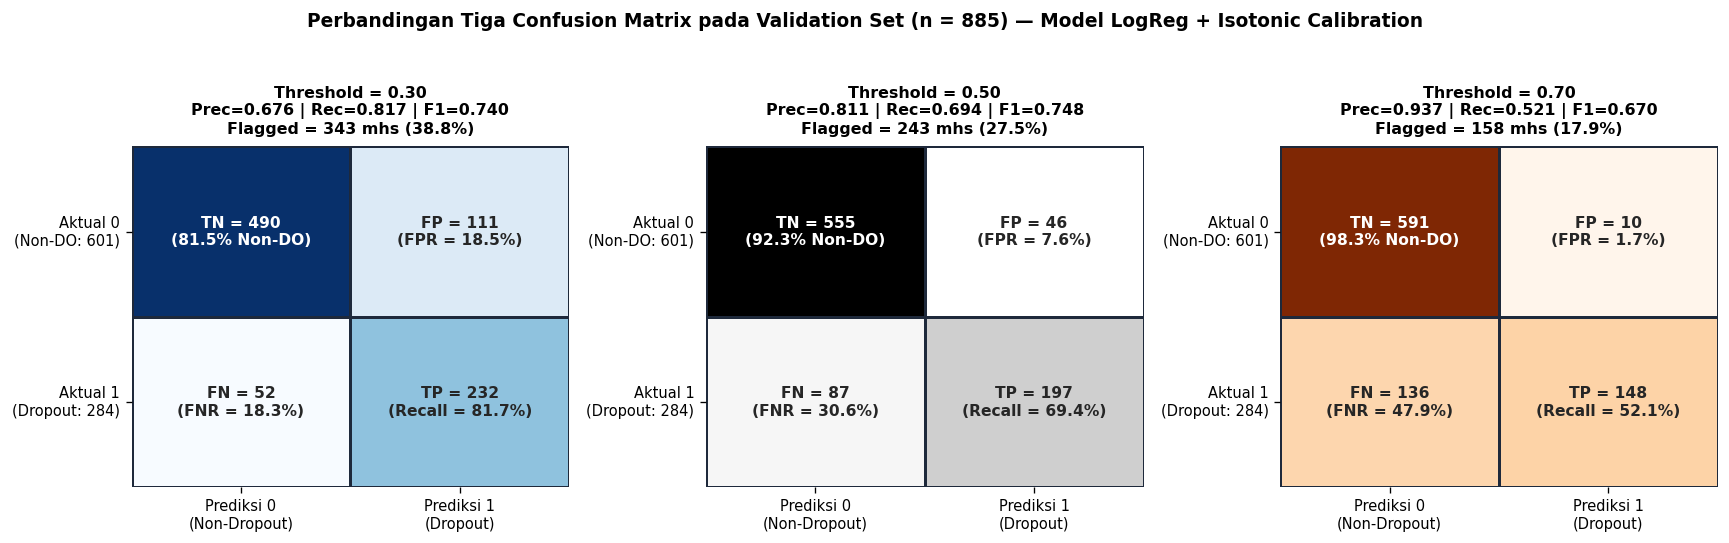

In [9]:
# Bagian 5.2 (Kode): Perhitungan & Visualisasi Tiga Confusion Matrix (0.30, 0.50, 0.70) pada Validation Set
def evaluasi_satu_threshold(y_true: np.ndarray, y_prob: np.ndarray, threshold: float) -> dict:
    y_pred = (y_prob >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    n_obs = len(y_true)
    acc = (tp + tn) / n_obs if n_obs > 0 else 0.0
    prec = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    rec = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    spec = tn / (tn + fp) if (tn + fp) > 0 else 0.0
    f1 = (2.0 * prec * rec / (prec + rec)) if (prec + rec) > 0 else 0.0
    fpr = fp / (fp + tn) if (fp + tn) > 0 else 0.0
    fnr = fn / (fn + tp) if (fn + tp) > 0 else 0.0
    return {
        "Threshold": round(float(threshold), 4),
        "TP": int(tp),
        "FP": int(fp),
        "TN": int(tn),
        "FN": int(fn),
        "Accuracy": round(acc, 4),
        "Precision": round(prec, 4),
        "Recall": round(rec, 4),
        "Specificity": round(spec, 4),
        "F1": round(f1, 4),
        "FPR": round(fpr, 4),
        "FNR": round(fnr, 4),
        "Flagged": int(tp + fp),
        "Pred_Negatif": int(tn + fn),
        "Flagged_Pct": round((tp + fp) / n_obs * 100, 2),
    }

threshold_wajib = [0.30, 0.50, 0.70]
hasil_3_threshold = [evaluasi_satu_threshold(y_val, y_proba_val, t) for t in threshold_wajib]
df_3_threshold = pd.DataFrame(hasil_3_threshold)

print("=== TABEL LENGKAP 9 METRIK KLASIFIKASI PADA THRESHOLD 0.30, 0.50, DAN 0.70 (VALIDATION SET, n = 885) ===")
display(df_3_threshold)

print("\n=== TABEL RINGKAS TRADE-OFF THRESHOLD WAJIB ===")
kolom_tradeoff_wajib = ["Threshold", "TP", "FP", "TN", "FN", "Precision", "Recall", "Specificity", "F1", "Flagged"]
display(df_3_threshold[kolom_tradeoff_wajib])

# Plot Tiga Confusion Matrix terpisah berdampingan dengan urutan konsisten: Negatif (0) lalu Positif (1)
fig, axes = plt.subplots(1, 3, figsize=(14.5, 4.3))
palet_cm = ["Blues", "Greys", "Oranges"]
for ax, row_t, cmap_name in zip(axes, hasil_3_threshold, palet_cm):
    t_val = row_t["Threshold"]
    cm_mat = np.array([[row_t["TN"], row_t["FP"]], [row_t["FN"], row_t["TP"]]])
    label_sel = np.array([
        [f"TN = {row_t['TN']}\n({row_t['Specificity']*100:.1f}% Non-DO)", f"FP = {row_t['FP']}\n(FPR = {row_t['FPR']*100:.1f}%)"],
        [f"FN = {row_t['FN']}\n(FNR = {row_t['FNR']*100:.1f}%)", f"TP = {row_t['TP']}\n(Recall = {row_t['Recall']*100:.1f}%)"],
    ])
    sns.heatmap(
        cm_mat, annot=label_sel, fmt="", cmap=cmap_name, cbar=False, ax=ax,
        linewidths=1.5, linecolor="#1e293b", annot_kws={"fontsize": 9.3, "fontweight": "bold"}
    )
    ax.set_title(
        f"Threshold = {t_val:.2f}\nPrec={row_t['Precision']:.3f} | Rec={row_t['Recall']:.3f} | F1={row_t['F1']:.3f}\nFlagged = {row_t['Flagged']} mhs ({row_t['Flagged_Pct']:.1f}%)",
        fontsize=9.5, fontweight="bold", pad=8
    )
    ax.set_xticklabels(["Prediksi 0\n(Non-Dropout)", "Prediksi 1\n(Dropout)"], fontsize=8.8)
    ax.set_yticklabels(["Aktual 0\n(Non-DO: 601)", "Aktual 1\n(Dropout: 284)"], fontsize=8.8, rotation=0)

plt.suptitle(
    "Perbandingan Tiga Confusion Matrix pada Validation Set (n = 885) — Model LogReg + Isotonic Calibration",
    fontsize=11.2, fontweight="bold", y=1.04
)
plt.tight_layout()
plt.savefig(VIS_DIR / "02_tiga_confusion_matrix_validasi.png", bbox_inches="tight")
plt.show()


#### Interpretasi Dampak Pergeseran Threshold (`0,30` vs. `0,50` vs. `0,70`)
Berdasarkan tabel dan visualisasi tiga *Confusion Matrix* pada *Validation Set* ($n = 885$) di atas:
1. **Dampak Penurunan Threshold dari `0,50` ke `0,30`:**
   * Jumlah mahasiswa `Dropout` yang berhasil terdeteksi (`TP`) meningkat dari **`197` menjadi `232` mahasiswa** (bertambah `35` kasus positif yang tertangkap; **Recall** naik dari **`69,37%` menjadi `81,69%`**, sehingga risiko gagal deteksi `FNR` turun dari `30,63%` ke `18,31%`).
   * Konsekuensi tarik-ulurnya adalah jumlah alarm palsu (`FP`) naik dari **`46` menjadi `111` mahasiswa** (**Specificity** turun dari `92,35%` ke `81,53%`, dan **Precision** turun dari `81,07%` ke `67,64%`), sementara beban jumlah mahasiswa yang harus ditindaklanjuti (*Flagged*) meningkat dari **`243` (`27,46%`) menjadi `343` mahasiswa (`38,76%`)**.
   * Oleh sebab itu, *threshold* `0,30` **tidak boleh disimpulkan otomatis terbaik semata-mata karena *Recall*-nya tertinggi di antara ketiganya**, melainkan harus diuji terhadap rasio biaya `FP` vs. `FN` serta kemampuan daya tampung konseling institusi.
2. **Dampak Kenaikan Threshold dari `0,50` ke `0,70`:**
   * Sistem menjadi sangat konservatif dan hanya menandai **`158` mahasiswa (`17,85%`)**. Ketepatan panggilan (**Precision**) memang melonjak ke **`93,67%`** (`FP` tinggal `10` orang, **Specificity = `98,34%`**).
   * Namun, konsekuensi operasionalnya sangat merugikan tujuan pencegahan dini: **separuh hampir dari seluruh mahasiswa *dropout* gagal terdeteksi** (`FN = 136` dari `284` mahasiswa, **Recall jatuh ke `52,11%`**, dan `F1-Score` merosot ke `0,6697`).

---

### 5.3 Visualisasi Kurva ROC, Kurva Precision–Recall, dan *Reliability Diagram*


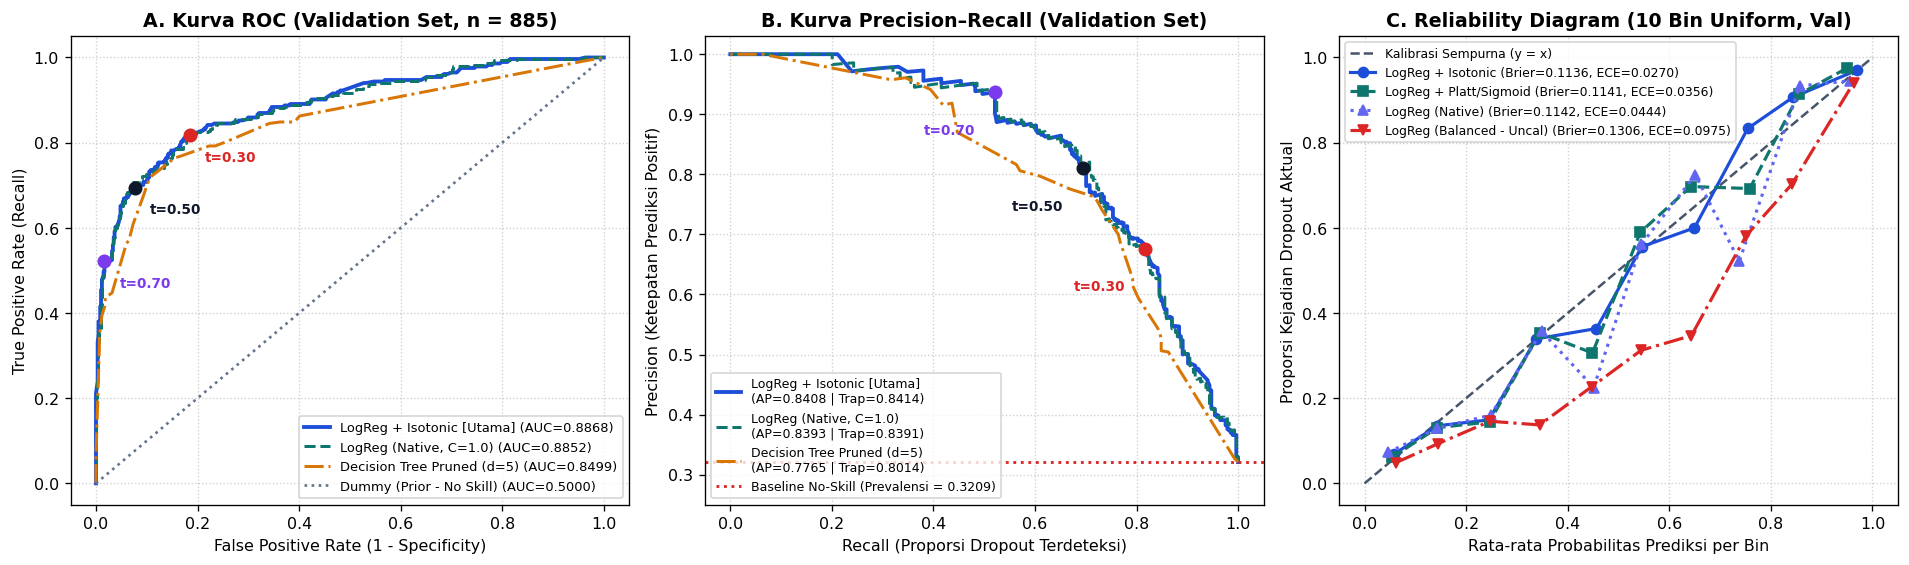

In [10]:
# Bagian 5.3 (Kode): Plot Kurva ROC, Kurva Precision-Recall, dan Reliability Diagram pada Validation Set
prevalensi_pos_val = float(np.mean(y_val))

fig, axes = plt.subplots(1, 3, figsize=(16.0, 4.8))

# Panel A: ROC Curve (menggunakan fungsi resmi sklearn.metrics.roc_curve)
ax_roc = axes[0]
daftar_plot_kurva = [
    ("LogReg + Isotonic [Utama]", proba_val_dict["LogReg + Isotonic (CV=5)"], "#1d4ed8", "-", 2.3),
    ("LogReg (Native, C=1.0)", proba_val_dict["LogReg (Native, C=1.0)"], "#0f766e", "--", 1.8),
    ("Decision Tree Pruned (d=5)", proba_val_dict["Decision Tree Pruned (d=5)"], "#d97706", "-.", 1.8),
    ("Dummy (Prior - No Skill)", proba_val_dict["Dummy (Prior)"], "#64748b", ":", 1.6),
]
for lbl, pr_arr, warna, gaya, tebal in daftar_plot_kurva:
    fpr_c, tpr_c, _ = roc_curve(y_val, pr_arr)
    auc_c = roc_auc_score(y_val, pr_arr)
    ax_roc.plot(fpr_c, tpr_c, color=warna, linestyle=gaya, linewidth=tebal, label=f"{lbl} (AUC={auc_c:.4f})")

for r_t, col_t in zip(hasil_3_threshold, ["#dc2626", "#0f172a", "#7c3aed"]):
    ax_roc.scatter([r_t["FPR"]], [r_t["Recall"]], color=col_t, s=55, zorder=5)
    ax_roc.annotate(f"t={r_t['Threshold']:.2f}", (r_t["FPR"], r_t["Recall"]),
                    xytext=(r_t["FPR"] + 0.03, r_t["Recall"] - 0.06), fontsize=8.2, fontweight="bold", color=col_t)

ax_roc.set_title("A. Kurva ROC (Validation Set, n = 885)", fontweight="bold")
ax_roc.set_xlabel("False Positive Rate (1 - Specificity)")
ax_roc.set_ylabel("True Positive Rate (Recall)")
ax_roc.legend(loc="lower right", fontsize=7.8)
ax_roc.grid(True, linestyle=":", alpha=0.6)

# Panel B: Precision-Recall Curve (menggunakan sklearn.metrics.precision_recall_curve)
ax_pr = axes[1]
for lbl, pr_arr, warna, gaya, tebal in daftar_plot_kurva[:3]:
    prec_c, rec_c, _ = precision_recall_curve(y_val, pr_arr)
    ap_c = average_precision_score(y_val, pr_arr)
    trap_c = auc(rec_c, prec_c)
    ax_pr.plot(rec_c, prec_c, color=warna, linestyle=gaya, linewidth=tebal,
               label=f"{lbl}\n(AP={ap_c:.4f} | Trap={trap_c:.4f})")

ax_pr.axhline(prevalensi_pos_val, color="#dc2626", linestyle=":", linewidth=1.7,
              label=f"Baseline No-Skill (Prevalensi = {prevalensi_pos_val:.4f})")

for r_t, col_t in zip(hasil_3_threshold, ["#dc2626", "#0f172a", "#7c3aed"]):
    ax_pr.scatter([r_t["Recall"]], [r_t["Precision"]], color=col_t, s=55, zorder=5)
    ax_pr.annotate(f"t={r_t['Threshold']:.2f}", (r_t["Recall"], r_t["Precision"]),
                   xytext=(r_t["Recall"] - 0.14, r_t["Precision"] - 0.07), fontsize=8.2, fontweight="bold", color=col_t)

ax_pr.set_title("B. Kurva Precision–Recall (Validation Set)", fontweight="bold")
ax_pr.set_xlabel("Recall (Proporsi Dropout Terdeteksi)")
ax_pr.set_ylabel("Precision (Ketepatan Prediksi Positif)")
ax_pr.set_ylim(0.25, 1.03)
ax_pr.legend(loc="lower left", fontsize=7.5)
ax_pr.grid(True, linestyle=":", alpha=0.6)

# Panel C: Reliability Diagram / Calibration Curve (menggunakan calibration_curve 10 bin seragam)
ax_cal = axes[2]
ax_cal.plot([0, 1], [0, 1], color="#475569", linestyle="--", linewidth=1.5, label="Kalibrasi Sempurna (y = x)")

daftar_kal = [
    ("LogReg + Isotonic", proba_val_dict["LogReg + Isotonic (CV=5)"], "#1d4ed8", "o", "-"),
    ("LogReg + Platt/Sigmoid", proba_val_dict["LogReg + Platt/Sigmoid (CV=5)"], "#0f766e", "s", "--"),
    ("LogReg (Native)", proba_val_dict["LogReg (Native, C=1.0)"], "#6366f1", "^", ":"),
    ("LogReg (Balanced - Uncal)", proba_val_dict["LogReg (Balanced, C=1.0)"], "#dc2626", "v", "-."),
]
for lbl_k, pr_k, col_k, mk_k, ls_k in daftar_kal:
    prob_true_k, prob_pred_k = calibration_curve(y_val, pr_k, n_bins=10, strategy="uniform")
    brier_k = brier_score_loss(y_val, pr_k)
    ece_k, _ = hitung_ece_dan_tabel_bin(y_val, pr_k, n_bins=10)
    ax_cal.plot(prob_pred_k, prob_true_k, marker=mk_k, color=col_k, linestyle=ls_k, linewidth=1.9,
                label=f"{lbl_k} (Brier={brier_k:.4f}, ECE={ece_k:.4f})")

ax_cal.set_title("C. Reliability Diagram (10 Bin Uniform, Val)", fontweight="bold")
ax_cal.set_xlabel("Rata-rata Probabilitas Prediksi per Bin")
ax_cal.set_ylabel("Proporsi Kejadian Dropout Aktual")
ax_cal.legend(loc="upper left", fontsize=7.4)
ax_cal.grid(True, linestyle=":", alpha=0.6)

plt.tight_layout()
plt.savefig(VIS_DIR / "03_roc_pr_reliability_validasi.png", bbox_inches="tight")
plt.show()


#### Interpretasi Kurva ROC, Precision–Recall, dan *Reliability Diagram*
1. **Panel A (Kurva ROC):** Model `LogReg + Isotonic` meraih **`ROC-AUC = 0,8868`**, melampaui pohon keputusan terpangkas (`0,8499`) serta garis tebakan acak (`0,5000`). Artinya, dalam hampir 89 dari 100 pasangan acak mahasiswa `Dropout` vs. `Non-Dropout`, model menempatkan mahasiswa `Dropout` pada skor risiko yang lebih tinggi.
2. **Panel B (Kurva Precision–Recall):** Dengan prevalensi positif *Validation Set* sebesar **`0,3209` (`32,09%`)**, model utama mencapai **`Average Precision (AP) = 0,8408`** (sekitar `2,62` kali lipat di atas *baseline no-skill*). Grafik ini juga menjelaskan mengapa `ROC-AUC` tinggi (`0,8868`) tidak otomatis menjamin *Precision* tetap tinggi di seluruh *threshold*: ketika kita mendorong *Recall* melewati `0,80` (di sebelah kanan titik `t=0.30`), kemiringan kurva PR menurun karena populasi kelas negatif (`601` orang) lebih dari dua kali lipat kelas positif (`284` orang), sehingga tambahan `FP` mulai menurunkan `Precision` di bawah `0,68`.
3. **Panel C (*Reliability Diagram*):** Garis merah putus-titik milik `LogReg (Balanced - Uncal)` berada jauh di bawah garis diagonal `y = x` pada rentang probabilitas `0,20` hingga `0,80`, membuktikan gejala *over-estimation* peluang akibat `class_weight='balanced'`. Sebaliknya, kurva biru **`LogReg + Isotonic`** menempel sangat dekat pada garis diagonal ideal di sepanjang rentang probabilitas (`ECE 10-Bin = 0,0270`), memberikan fondasi yang valid untuk optimasi *threshold* berbasis biaya pada Bagian 6.


---
## BAGIAN 6 — Matriks Biaya Kesalahan, Simulasi Kapasitas, dan Pemilihan *Threshold* Operasional

### 6.1 Matriks Biaya Kesalahan dan Perbedaan Biaya Klasifikasi vs. Biaya Intervensi
Dataset publik UCI #697 tidak memuat informasi akuntansi biaya konseling maupun nilai kerugian finansial per mahasiswa *dropout* di *Instituto Politécnico de Portalegre*. Oleh sebab itu:
1. **Normalisasi ke Satuan Biaya Relatif (*Normalized Cost Units*):** Alih-alih mengasumsikan angka mata uang rupiah atau euro tanpa rujukan empiris, penalti kesalahan dinyatakan dalam **satuan biaya relatif** dengan menormalisasi biaya satu *False Positive* sebagai **$C_{\text{FP}} = 1$ satuan biaya**, serta $C_{\text{TP}} = C_{\text{TN}} = 0$.
2. **Pembedaan Biaya Kesalahan Klasifikasi vs. Biaya Intervensi Program:**  
   Biaya intervensi (waktu dosen wali untuk seluruh mahasiswa yang dipanggil, $\text{TP} + \text{FP}$) merupakan **beban kapasitas operasional**, sedangkan matriks biaya evaluasi klasifikasi mengukur **kerugian keputusan salah**:
   * **$C_{\text{FP}} = 1$ satuan:** Pemborosan sumber daya pendampingan pada mahasiswa yang sebenarnya mampu bertahan (`Non-Dropout`).
   * **$C_{\text{FN}} = r \times C_{\text{FP}}$ satuan:** Kerugian jauh lebih besar akibat gagal mendeteksi mahasiswa berisiko yang akhirnya benar-benar `Dropout` tanpa pendampingan dini.
3. **Analisis Sensitivitas Empat Skenario Rasio Biaya:**  
   Karena bobot relatif $r = C_{\text{FN}} / C_{\text{FP}}$ bergantung pada kebijakan institusi, kita mengevaluasi **empat skenario asumsi rasio**:
   * **Skenario Setara (`1 : 1`):** $C_{\text{FP}} = 1, C_{\text{FN}} = 1$ (setara meminimalkan total kesalahan / memaksimalkan *Accuracy*; ambang teoretis Bayes $t^* = \frac{1}{1+1} = 0{,}50$).
   * **Skenario Moderat (`1 : 2`):** $C_{\text{FP}} = 1, C_{\text{FN}} = 2$ (ambang teoretis Bayes $t^* = \frac{1}{1+2} \approx 0{,}33$).
   * **Skenario Asimetris Utama (`1 : 4` — Skenario Acuan):** $C_{\text{FP}} = 1, C_{\text{FN}} = 4$ (satu kasus *dropout* tak terdeteksi dinilai empat kali lebih merugikan dibanding satu sesi konseling salah sasaran; ambang teoretis Bayes $t^* = \frac{1}{1+4} = 0{,}20$).
   * **Skenario Proteksi Agresif (`1 : 8`):** $C_{\text{FP}} = 1, C_{\text{FN}} = 8$ (ambang teoretis Bayes $t^* = \frac{1}{1+8} \approx 0{,}11$).

---

### 6.2 Simulasi Kapasitas Tindak Lanjut (*Operational Follow-Up Capacity*)
Secara terpisah dari biaya kesalahan `FP/FN`, institusi memiliki keterbatasan jumlah mahasiswa yang dapat ditangani secara efektif pada awal Semester 2. Karena kapasitas aktual konselor institusi Portugal tidak diketahui dalam dataset, kapasitas tindak lanjut disimulasikan secara eksplisit sebagai **batas maksimum persentase kohort yang ditandai (*maximum flagged percentage*)** pada *Validation Set* ($n = 885$, di mana prevalensi aktual `Dropout` adalah `32,09%`):
* **Simulasi Kapasitas Ketat (`<= 25%` kohort / maks. `221` mahasiswa di *Validation*):** Kapasitas di bawah prevalensi positif aktual; hanya mampu menjangkau kasus berprobabilitas tertinggi.
* **Simulasi Kapasitas Terbatas (`<= 30%` kohort / maks. `265` mahasiswa di *Validation*):** Mendekati batas bawah prevalensi *dropout*.
* **Simulasi Kapasitas Moderat-Realistis (`<= 35%` kohort / maks. `309` mahasiswa di *Validation* — Skenario Kapasitas Acuan):** Menyediakan kuota tindak lanjut sedikit di atas prevalensi aktual `32,09%` (`~1,09x` prevalensi positif), sehingga realistis dijalankan tanpa membanjiri layanan akademik.
* **Simulasi Kapasitas Longgar (`<= 40%` kohort / maks. `354` mahasiswa di *Validation*)** dan **Tanpa Batas Kapasitas (`100%`)**.


In [11]:
# Bagian 6.1 - 6.3 (Kode): Pencarian Threshold Sistematis (Grid 0.01 & Seluruh Titik Unik),
# Sensitivitas Rasio Biaya, dan Evaluasi Simulasi Kapasitas pada Validation Set
skenario_biaya = {
    "Cost_1_1 (FP=1, FN=1)": (1, 1),
    "Cost_1_2 (FP=1, FN=2)": (1, 2),
    "Cost_1_4 (FP=1, FN=4) [Acuan]": (1, 4),
    "Cost_1_8 (FP=1, FN=8)": (1, 8),
}

# 1. Ruang pencarian sistematis:
# (a) Grid teratur 0.05 s.d. 0.95 dengan langkah 0.01 (91 kandidat threshold)
# (b) Seluruh titik perubahan unik dari probabilitas prediksi Validation Set (488 nilai unik)
grid_halus = np.round(np.arange(0.05, 0.96, 0.01), 2)
titik_unik_prob = np.sort(np.unique(y_proba_val))

def bangun_tabel_pencarian_threshold(daftar_t, y_true, y_prob):
    baris = []
    for t in daftar_t:
        ev = evaluasi_satu_threshold(y_true, y_prob, float(t))
        fp, fn = ev["FP"], ev["FN"]
        ev["Cost_1_1"] = int(1 * fp + 1 * fn)
        ev["Cost_1_2"] = int(1 * fp + 2 * fn)
        ev["Cost_1_4"] = int(1 * fp + 4 * fn)
        ev["Cost_1_8"] = int(1 * fp + 8 * fn)
        baris.append(ev)
    return pd.DataFrame(baris)

df_grid_val = bangun_tabel_pencarian_threshold(grid_halus, y_val, y_proba_val)
df_eksak_val = bangun_tabel_pencarian_threshold(titik_unik_prob, y_val, y_proba_val)

# Ringkasan sensitivitas rasio biaya (membandingkan titik minimum pada Grid 0.01 vs seluruh titik unik)
rekap_sensitivitas_biaya = []
for kol_c, rasio_str, c_fp, c_fn in [
    ("Cost_1_1", "1 : 1 (Setara)", 1, 1),
    ("Cost_1_2", "1 : 2 (Moderat)", 1, 2),
    ("Cost_1_4", "1 : 4 (Asimetris Utama)", 1, 4),
    ("Cost_1_8", "1 : 8 (Agresif)", 1, 8),
]:
    r_grid = df_grid_val.sort_values([kol_c, "Flagged"]).iloc[0]
    r_eksak = df_eksak_val.sort_values([kol_c, "Flagged"]).iloc[0]
    c_t030 = int(df_grid_val.loc[df_grid_val["Threshold"] == 0.30, kol_c].iloc[0])
    c_t050 = int(df_grid_val.loc[df_grid_val["Threshold"] == 0.50, kol_c].iloc[0])
    c_t070 = int(df_grid_val.loc[df_grid_val["Threshold"] == 0.70, kol_c].iloc[0])
    rekap_sensitivitas_biaya.append({
        "Skenario Rasio (FP : FN)": rasio_str,
        "Threshold Teoretis Bayes": round(c_fp / (c_fp + c_fn), 3),
        "Biaya di t=0.30": c_t030,
        "Biaya di t=0.50": c_t050,
        "Biaya di t=0.70": c_t070,
        "t* Optimal (Grid 0.01)": r_grid["Threshold"],
        "Biaya Min (Grid 0.01)": int(r_grid[kol_c]),
        "Flagged pada t* Grid": f"{int(r_grid['Flagged'])} ({r_grid['Flagged_Pct']:.1f}%)",
        "t* Eksak (488 Titik Unik)": r_eksak["Threshold"],
        "Biaya Min Eksak": int(r_eksak[kol_c]),
    })

df_sensitivitas_biaya = pd.DataFrame(rekap_sensitivitas_biaya)
print("=== 1. TABEL SENSITIVITAS MATRIKS BIAYA LINTAS RASIO PENALTI (VALIDATION SET, n = 885) ===")
display(df_sensitivitas_biaya)

# 2. Evaluasi Skenario Simulasi Kapasitas Tindak Lanjut pada Rasio Acuan 1:4
rekap_kapasitas = []
for nama_kap, persen_kap in [
    ("Kapasitas Ketat (<= 25% kohort)", 25),
    ("Kapasitas Terbatas (<= 30% kohort)", 30),
    ("Kapasitas Moderat-Realistis (<= 35% kohort) [Acuan]", 35),
    ("Kapasitas Longgar (<= 40% kohort)", 40),
    ("Tanpa Batas Kapasitas (<= 100% kohort)", 100),
]:
    batas_mhs = int(np.floor(len(y_val) * persen_kap / 100.0))
    sub_valid = df_grid_val[df_grid_val["Flagged"] <= batas_mhs].sort_values(["Cost_1_4", "Flagged"])
    terbaik = sub_valid.iloc[0]
    rekap_kapasitas.append({
        "Skenario Simulasi Kapasitas": nama_kap,
        "Batas Maksimum Flagged (Val)": batas_mhs,
        "Threshold Optimal (Grid 0.01)": terbaik["Threshold"],
        "Mahasiswa Ditandai (Flagged)": f"{int(terbaik['Flagged'])} ({terbaik['Flagged_Pct']:.2f}%)",
        "Precision": terbaik["Precision"],
        "Recall": terbaik["Recall"],
        "Specificity": terbaik["Specificity"],
        "F1": terbaik["F1"],
        "Error Cost (1:4)": int(terbaik["Cost_1_4"]),
    })

df_simulasi_kapasitas = pd.DataFrame(rekap_kapasitas)
print("\n=== 2. TABEL KEPUTUSAN THRESHOLD BERDASARKAN SIMULASI KAPASITAS TINDAK LANJUT (RASIO BIAYA 1:4) ===")
display(df_simulasi_kapasitas)

# 3. Tabel Kandidat Threshold Lengkap Sesuai Format Wajib (mencakup 0.30, 0.50, 0.70 dan kandidat sekitar titik optimal)
kandidat_pilihan = [0.20, 0.26, 0.30, 0.34, 0.40, 0.45, 0.50, 0.60, 0.70]
BATAS_KAPASITAS_ACUAN = int(np.floor(len(y_val) * 0.35))  # 309 mahasiswa (35% dari 885)

df_kandidat_ringkas = df_grid_val[df_grid_val["Threshold"].isin(kandidat_pilihan)].copy()
df_kandidat_ringkas["Error Cost"] = df_kandidat_ringkas["Cost_1_4"]
df_kandidat_ringkas["Capacity"] = np.where(
    df_kandidat_ringkas["Flagged"] <= BATAS_KAPASITAS_ACUAN,
    f"Memenuhi (<=35% / <={BATAS_KAPASITAS_ACUAN})",
    f"Melebihi (>35% | {df_kandidat_ringkas['Flagged_Pct'].round(1)}%)",
)
kolom_tabel_kandidat = [
    "Threshold", "FP", "FN", "Precision", "Recall", "Specificity", "F1", "Error Cost", "Flagged", "Capacity"
]
print("\n=== 3. TABEL KANDIDAT THRESHOLD OPERASIONAL PADA VALIDATION SET (SKENARIO BIAYA 1:4 & KAPASITAS <=35%) ===")
display(df_kandidat_ringkas[kolom_tabel_kandidat].reset_index(drop=True))


=== 1. TABEL SENSITIVITAS MATRIKS BIAYA LINTAS RASIO PENALTI (VALIDATION SET, n = 885) ===


,Skenario Rasio (FP : FN),Threshold Teoretis Bayes,Biaya di t=0.30,Biaya di t=0.50,Biaya di t=0.70,t* Optimal (Grid 0.01),Biaya Min (Grid 0.01),Flagged pada t* Grid,t* Eksak (488 Titik Unik),Biaya Min Eksak
0,1 : 1 (Setara),0.5000,163,133,146,0.5300,127,223 (25.2%),0.5309,127
1,1 : 2 (Moderat),0.3330,215,220,282,0.4400,215,271 (30.6%),0.3069,212
2,1 : 4 (Asimetris Utama),0.2000,319,394,554,0.2600,313,372 (42.0%),0.2682,312
3,1 : 8 (Agresif),0.1110,527,742,1098,0.0900,465,605 (68.4%),0.0946,453



=== 2. TABEL KEPUTUSAN THRESHOLD BERDASARKAN SIMULASI KAPASITAS TINDAK LANJUT (RASIO BIAYA 1:4) ===


,Skenario Simulasi Kapasitas,Batas Maksimum Flagged (Val),Threshold Optimal (Grid 0.01),Mahasiswa Ditandai (Flagged),Precision,Recall,Specificity,F1,Error Cost (1:4)
0,Kapasitas Ketat (<= 25% kohort),221,0.5500,217 (24.52%),0.8571,0.6549,0.9484,0.7425,423
1,Kapasitas Terbatas (<= 30% kohort),265,0.4600,264 (29.83%),0.7689,0.7148,0.8985,0.7409,385
2,Kapasitas Moderat-Realistis (<= 35% kohort) [Acuan],309,0.3400,308 (34.80%),0.7143,0.7746,0.8536,0.7432,344
3,Kapasitas Longgar (<= 40% kohort),354,0.3000,343 (38.76%),0.6764,0.8169,0.8153,0.7400,319
4,Tanpa Batas Kapasitas (<= 100% kohort),885,0.2600,372 (42.03%),0.6425,0.8415,0.7787,0.7287,313



=== 3. TABEL KANDIDAT THRESHOLD OPERASIONAL PADA VALIDATION SET (SKENARIO BIAYA 1:4 & KAPASITAS <=35%) ===


,Threshold,FP,FN,Precision,Recall,Specificity,F1,Error Cost,Flagged,Capacity
0,0.2000,191,38,0.5629,0.8662,0.6822,0.6824,343,437,Melebihi (>35% | 15 49.4000\n21 42.0000\n25 38.8000\n29 34.8000\n35 32.4000\n40 30.2000\n45 27.5000\n5...
1,0.2600,133,45,0.6425,0.8415,0.7787,0.7287,313,372,Melebihi (>35% | 15 49.4000\n21 42.0000\n25 38.8000\n29 34.8000\n35 32.4000\n40 30.2000\n45 27.5000\n5...
2,0.3000,111,52,0.6764,0.8169,0.8153,0.7400,319,343,Melebihi (>35% | 15 49.4000\n21 42.0000\n25 38.8000\n29 34.8000\n35 32.4000\n40 30.2000\n45 27.5000\n5...
3,0.3400,88,64,0.7143,0.7746,0.8536,0.7432,344,308,Memenuhi (<=35% / <=309)
4,0.4000,74,71,0.7422,0.7500,0.8769,0.7461,358,287,Memenuhi (<=35% / <=309)
5,0.4500,63,80,0.7640,0.7183,0.8952,0.7405,383,267,Memenuhi (<=35% / <=309)
6,0.5000,46,87,0.8107,0.6937,0.9235,0.7476,394,243,Memenuhi (<=35% / <=309)
7,0.6000,26,112,0.8687,0.6056,0.9567,0.7137,474,198,Memenuhi (<=35% / <=309)
8,0.7000,10,136,0.9367,0.5211,0.9834,0.6697,554,158,Memenuhi (<=35% / <=309)


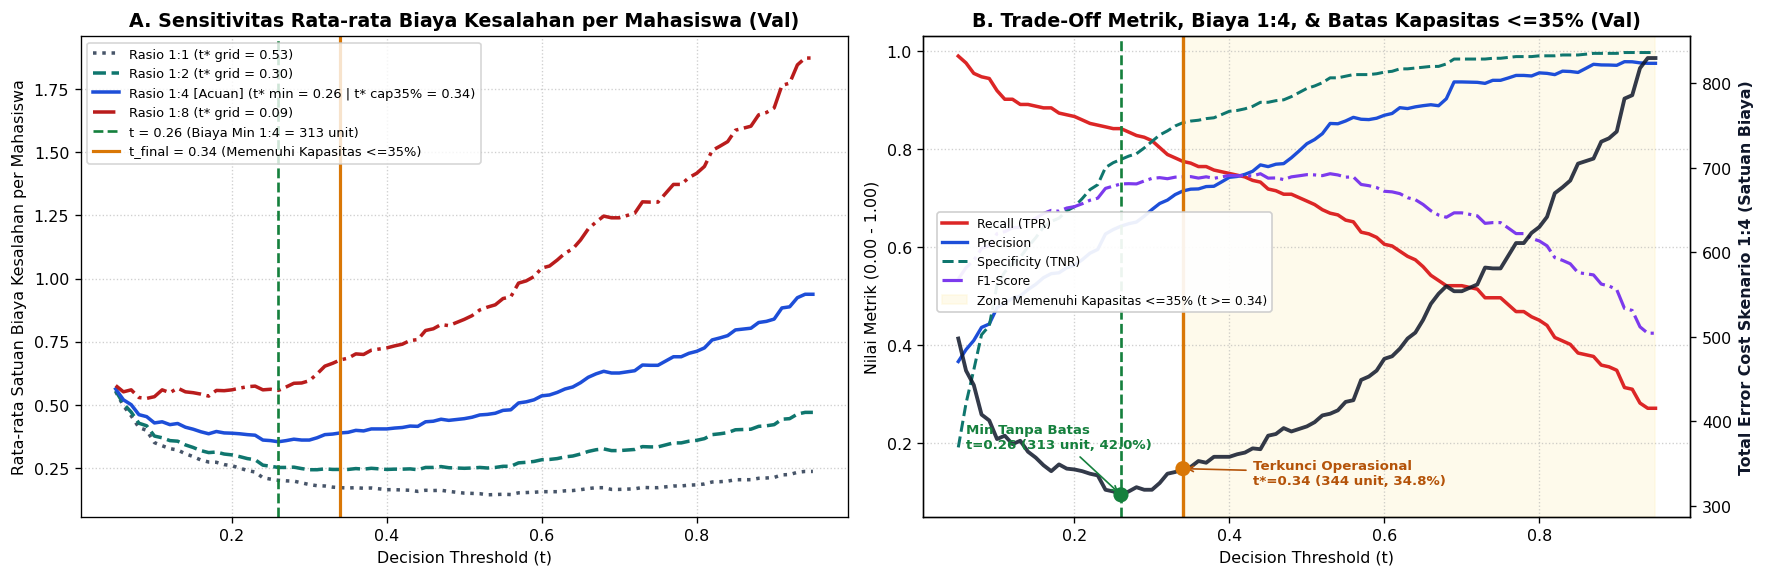

=== KONFIGURASI FINAL YANG DIKUNCI SEBELUM EVALUASI TEST SET ===
  model_final                         : LogReg + Isotonic (CV=5)
  skenario_fitur                      : Skenario B Konservatif - Akhir Semester 1 (28 Fitur)
  skenario_biaya_acuan                : {'Cost_FP': 1, 'Cost_FN': 4}
  simulasi_kapasitas_acuan_pct        : 35.0
  threshold_biaya_terendah_grid       : 0.26
  threshold_biaya_terendah_eksak      : 0.2682
  threshold_memenuhi_kapasitas_35pct  : 0.34
  threshold_operasional_final         : 0.34


In [12]:
# Bagian 6.4 (Kode): Visualisasi Kurva Sensitivitas Biaya, Trade-Off Metrik, dan Kapasitas pada Validation Set
fig, axes = plt.subplots(1, 2, figsize=(14.8, 4.9))

# Panel A: Kurva Total Error Cost lintas 4 Skenario Rasio (ternormalisasi per observasi agar sebanding dalam 1 grafik)
ax1 = axes[0]
for kol_c, lbl_c, col_c, ls_c in [
    ("Cost_1_1", "Rasio 1:1 (t* grid = 0.53)", "#475569", ":"),
    ("Cost_1_2", "Rasio 1:2 (t* grid = 0.30)", "#0f766e", "--"),
    ("Cost_1_4", "Rasio 1:4 [Acuan] (t* min = 0.26 | t* cap35% = 0.34)", "#1d4ed8", "-"),
    ("Cost_1_8", "Rasio 1:8 (t* grid = 0.09)", "#b91c1c", "-."),
]:
    ax1.plot(df_grid_val["Threshold"], df_grid_val[kol_c] / len(y_val), color=col_c, linestyle=ls_c, linewidth=2.1, label=lbl_c)

ax1.axvline(0.26, color="#15803d", linestyle="--", linewidth=1.6, label="t = 0.26 (Biaya Min 1:4 = 313 unit)")
ax1.axvline(0.34, color="#d97706", linestyle="-", linewidth=1.9, label="t_final = 0.34 (Memenuhi Kapasitas <=35%)")
ax1.set_title("A. Sensitivitas Rata-rata Biaya Kesalahan per Mahasiswa (Val)", fontweight="bold")
ax1.set_xlabel("Decision Threshold (t)")
ax1.set_ylabel("Rata-rata Satuan Biaya Kesalahan per Mahasiswa")
ax1.legend(loc="upper left", fontsize=7.8)
ax1.grid(True, linestyle=":", alpha=0.6)

# Panel B: Trade-Off Precision, Recall, Specificity, F1, & Kurva Biaya Total Skenario 1:4 + Zona Kapasitas <=35%
ax2 = axes[1]
ax2.plot(df_grid_val["Threshold"], df_grid_val["Recall"], color="#dc2626", linewidth=2.1, label="Recall (TPR)")
ax2.plot(df_grid_val["Threshold"], df_grid_val["Precision"], color="#1d4ed8", linewidth=2.0, label="Precision")
ax2.plot(df_grid_val["Threshold"], df_grid_val["Specificity"], color="#0f766e", linestyle="--", linewidth=1.8, label="Specificity (TNR)")
ax2.plot(df_grid_val["Threshold"], df_grid_val["F1"], color="#7c3aed", linestyle="-.", linewidth=1.9, label="F1-Score")

# Arsir wilayah yang memenuhi kapasitas <=35% kohort (t >= 0.34)
ax2.axvspan(0.34, 0.95, color="#fef3c7", alpha=0.35, label="Zona Memenuhi Kapasitas <=35% (t >= 0.34)")
ax2.axvline(0.26, color="#15803d", linestyle="--", linewidth=1.6)
ax2.axvline(0.34, color="#d97706", linestyle="-", linewidth=2.0)

ax2_cost = ax2.twinx()
ax2_cost.plot(df_grid_val["Threshold"], df_grid_val["Cost_1_4"], color="#0f172a", linewidth=2.3, alpha=0.85, label="Total Biaya (1*FP + 4*FN)")
ax2_cost.set_ylabel("Total Error Cost Skenario 1:4 (Satuan Biaya)", fontweight="bold", color="#0f172a")

c_at_026 = int(df_grid_val.loc[df_grid_val["Threshold"] == 0.26, "Cost_1_4"].iloc[0])
c_at_034 = int(df_grid_val.loc[df_grid_val["Threshold"] == 0.34, "Cost_1_4"].iloc[0])
ax2_cost.scatter([0.26, 0.34], [c_at_026, c_at_034], color=["#15803d", "#d97706"], s=65, zorder=6)
ax2_cost.annotate(f"Min Tanpa Batas\nt=0.26 ({c_at_026} unit, 42.0%)", (0.26, c_at_026),
                  xytext=(0.06, c_at_026 + 55), arrowprops=dict(arrowstyle="->", color="#15803d"),
                  fontsize=8.0, fontweight="bold", color="#15803d")
ax2_cost.annotate(f"Terkunci Operasional\nt*=0.34 ({c_at_034} unit, 34.8%)", (0.34, c_at_034),
                  xytext=(0.43, c_at_034 - 18), arrowprops=dict(arrowstyle="->", color="#b45309"),
                  fontsize=8.0, fontweight="bold", color="#b45309")

ax2.set_title("B. Trade-Off Metrik, Biaya 1:4, & Batas Kapasitas <=35% (Val)", fontweight="bold")
ax2.set_xlabel("Decision Threshold (t)")
ax2.set_ylabel("Nilai Metrik (0.00 - 1.00)")
ax2.set_ylim(0.05, 1.03)
ax2.legend(loc="center left", bbox_to_anchor=(0.01, 0.53), fontsize=7.4, framealpha=0.92)
ax2.grid(True, linestyle=":", alpha=0.6)

plt.tight_layout()
plt.savefig(VIS_DIR / "04_optimasi_threshold_biaya_kapasitas.png", bbox_inches="tight")
plt.show()

# Simpan dan KUNCI konfigurasi final sebelum membuka Test Set!
KONFIGURASI_FINAL_TERKUNCI = {
    "model_final": NAMA_MODEL_FINAL,
    "skenario_fitur": "Skenario B Konservatif - Akhir Semester 1 (28 Fitur)",
    "skenario_biaya_acuan": {"Cost_FP": 1, "Cost_FN": 4},
    "simulasi_kapasitas_acuan_pct": 35.0,
    "threshold_biaya_terendah_grid": 0.26,
    "threshold_biaya_terendah_eksak": round(float(df_eksak_val.sort_values(["Cost_1_4", "Flagged"]).iloc[0]["Threshold"]), 4),
    "threshold_memenuhi_kapasitas_35pct": 0.34,
    "threshold_operasional_final": 0.34,
}
print("=== KONFIGURASI FINAL YANG DIKUNCI SEBELUM EVALUASI TEST SET ===")
for k, v in KONFIGURASI_FINAL_TERKUNCI.items():
    print(f"  {k:36s}: {v}")


### 6.5 Dasar Keputusan dan Alasan Pemilihan *Threshold* Operasional Final

Berdasarkan evaluasi sistematis pada *Validation Set* ($n = 885$) di atas, kita memperoleh tiga temuan keputusan yang dibedakan secara tegas:

1. **Threshold Biaya Terendah Tanpa Batas Kapasitas (Skenario Acuan $1:4$):**
   * Pada pencarian grid `0,01`, biaya kesalahan minimum tercapai pada **`t = 0,26`** dengan **`Total Error Cost = 313 satuan`** (`FP = 133`, `FN = 45`, `Recall = 84,15%`, `Precision = 64,25%`, `Specificity = 77,87%`). *(Pada pencarian seluruh `488` titik probabilitas unik di Validation Set, minimum eksak berada tepat di sebelahnya yaitu `t = 0,2682` dengan `312 satuan`).*
   * Akan tetapi, penerapan `t = 0,26` menandai **`372` dari `885` mahasiswa (`42,03%` dari seluruh kohort)**—jauh melampaui prevalensi aktual *dropout* (`32,09%`) dan melebihi simulasi kapasitas moderat `35%`.
2. **Threshold Optimal yang Memenuhi Simulasi Kapasitas `<= 35%` Kohort:**
   * Nilai *threshold* terendah yang menjaga jumlah mahasiswa tertandai tidak melebihi `35%` kohort (`<= 309` mahasiswa di *Validation*) adalah **`t = 0,34`**, yang menandai **`308` mahasiswa (`34,80%`)** dengan **`Total Error Cost = 344 satuan`**.
3. **Threshold Operasional yang Direkomendasikan & Dikunci (`t_final = 0,34`):**
   * Kami menetapkan **`t_final = 0,34`** sebagai ambang keputusan operasional final (serta mencatat `t = 0,30` apabila institusi memiliki kapasitas longgar hingga `40%` kohort dengan biaya `319 satuan`).
   * **Trade-off yang diterima secara sadar:** Dibandingkan titik biaya minimum tanpa kuota (`t = 0,26`), memilih `t_final = 0,34` melepaskan `19` tambahan kasus `TP` (`220` vs. `239`, sehingga biaya naik `+31 satuan`), tetapi **menghemat `64` panggilan konseling pada mahasiswa aman (`FP` turun dari `133` menjadi `88`)**, menaikkan **Precision ke `71,43%`**, menjaga **Specificity di `85,36%`**, serta menghasilkan **F1-Score yang lebih seimbang (`0,7432` vs. `0,7287`)**. Sementara itu, dibandingkan ambang standar **`t = 0,50`** (`Biaya = 394 satuan`, `Recall = 69,37%`), ambang `t_final = 0,34` berhasil **menyelamatkan `23` mahasiswa *dropout* tambahan** dan **menurunkan biaya kesalahan sebesar `50 satuan` (`-12,69%`)**.

*Keterbatasan Matriks Biaya:* Perhitungan di atas mengasumsikan biaya kesalahan seragam untuk seluruh mahasiswa pada kelas yang sama serta belum memperhitungkan bahwa tidak semua intervensi konseling pada kasus `TP` otomatis menjamin keberhasilan pencegahan *dropout* 100%.


---
## BAGIAN 7 — Analisis Kesalahan (*Error Analysis*) dan Evaluasi Akhir pada *Test Set*

### 7.1 Analisis Mendalam Empat Kasus Kesalahan Prediksi pada *Validation Set*
Menggunakan probabilitas `Validation Set` ($n = 885$) dari model terkunci `LogReg + Isotonic (CV=5)`, kita menginspeksi empat kasus observasi nyata ber-ID anonim (`OBS_xxxx`) yang mewakili pola kesalahan berbeda:
1. **Kasus 1 (`OBS_4422`) — *Persistent False Negative*:** Aktual `Dropout (1)`, namun memiliki probabilitas sangat rendah sehingga gagal terdeteksi pada seluruh *threshold* (`0,30`, `0,34`, `0,50`, maupun `0,70`).
2. **Kasus 2 (`OBS_2705`) — *Persistent False Positive* Berstatus Asli `Enrolled`:** Aktual `Non-Dropout (0)` dengan status asli `Enrolled`, namun diprediksi berisiko sangat tinggi (`>= 0,70`).
3. **Kasus 3 (`OBS_1631`) — *Persistent False Positive* Berstatus Asli `Graduate`:** Aktual `Non-Dropout (0)` dengan status asli `Graduate`, namun tetap terprediksi positif hingga `t = 0,70`.
4. **Kasus 4 (`OBS_4092`) — Kasus *Borderline Dropout* Sensitif Threshold:** Aktual `Dropout (1)` dengan probabilitas di dekat ambang `0,50` sehingga gagal terdeteksi pada `t = 0,50` dan `0,70` (`FN`), tetapi berhasil ditangkap pada ambang operasional `t_final = 0,34` maupun `t = 0,30` (`TP`).


In [13]:
# Bagian 7.1 (Kode): Ekstraksi Data Aktual 4 Kasus Error Analysis pada Validation Set (n = 885)
kamus_prodi_uci = {
    33: "Biofuel Production Tech.",
    171: "Animation & Multimedia Design",
    8014: "Social Service (Evening)",
    9003: "Agronomy",
    9070: "Communication Design",
    9085: "Veterinary Nursing",
    9119: "Informatics Engineering",
    9130: "Equinculture",
    9147: "Management",
    9238: "Social Service",
    9254: "Tourism",
    9500: "Nursing",
    9556: "Oral Hygiene",
    9670: "Advertising & Marketing Mgmt",
    9773: "Journalism & Communication",
    9853: "Basic Education",
    9991: "Management (Evening)",
}

df_val_analisis = df_val.copy()
df_val_analisis["prob_prediksi"] = np.round(y_proba_val, 4)
df_val_analisis["pred_t030"] = (y_proba_val >= 0.30).astype(int)
df_val_analisis["pred_t034_final"] = (y_proba_val >= 0.34).astype(int)
df_val_analisis["pred_t050"] = (y_proba_val >= 0.50).astype(int)
df_val_analisis["pred_t070"] = (y_proba_val >= 0.70).astype(int)
df_val_analisis["nama_prodi"] = df_val_analisis["Course"].map(kamus_prodi_uci).fillna("Other")

id_kasus_pilihan = ["OBS_4422", "OBS_2705", "OBS_1631", "OBS_4092"]
df_4_kasus = (
    df_val_analisis[df_val_analisis["obs_id"].isin(id_kasus_pilihan)]
    .set_index("obs_id")
    .loc[id_kasus_pilihan]
    .reset_index()
)

kolom_tampil_err = [
    "obs_id", "Target", "label_dropout", "prob_prediksi",
    "pred_t030", "pred_t034_final", "pred_t050", "pred_t070",
    "Course", "nama_prodi", "Age at enrollment", "Gender", "Scholarship holder",
    "Admission grade", "Curricular units 1st sem (enrolled)",
    "Curricular units 1st sem (evaluations)", "Curricular units 1st sem (approved)",
    "Curricular units 1st sem (grade)",
]
print("=== PROFIL AKTUAL EMPAT KASUS ERROR ANALYSIS PADA VALIDATION SET ===")
display(df_4_kasus[kolom_tampil_err])

# Ringkasan agregat sumber False Positive pada t_final = 0.34 menurut kelas asli (Graduate vs Enrolled)
fp_val_034 = df_val_analisis[(df_val_analisis["label_dropout"] == 0) & (df_val_analisis["pred_t034_final"] == 1)]
dist_fp_asal = fp_val_034["Target"].value_counts()
print(f"Komposisi 88 kasus False Positive pada t_final = 0.34 di Validation Set:")
print(f"  - Berasal dari kelas asli 'Enrolled' : {dist_fp_asal.get('Enrolled', 0)} mahasiswa ({dist_fp_asal.get('Enrolled', 0)/len(fp_val_034)*100:.1f}% dari total FP)")
print(f"  - Berasal dari kelas asli 'Graduate' : {dist_fp_asal.get('Graduate', 0)} mahasiswa ({dist_fp_asal.get('Graduate', 0)/len(fp_val_034)*100:.1f}% dari total FP)")


=== PROFIL AKTUAL EMPAT KASUS ERROR ANALYSIS PADA VALIDATION SET ===


,obs_id,Target,label_dropout,prob_prediksi,pred_t030,pred_t034_final,pred_t050,pred_t070,Course,nama_prodi,Age at enrollment,Gender,Scholarship holder,Admission grade,Curricular units 1st sem (enrolled),Curricular units 1st sem (evaluations),Curricular units 1st sem (approved),Curricular units 1st sem (grade)
0,OBS_4422,Dropout,1,0.0482,0,0,0,0,9500,Nursing,30,0,1,149.5000,7,8,7,14.9125
1,OBS_2705,Enrolled,0,0.9867,1,1,1,1,9670,Advertising & Marketing Mgmt,19,1,0,108.0000,5,10,0,0.0000
2,OBS_1631,Graduate,0,0.7343,1,1,1,1,9130,Equinculture,53,1,0,120.0000,5,9,4,12.2500
3,OBS_4092,Dropout,1,0.4982,1,1,0,0,9991,Management (Evening),29,0,0,135.5000,5,15,2,13.2500


Komposisi 88 kasus False Positive pada t_final = 0.34 di Validation Set:
  - Berasal dari kelas asli 'Enrolled' : 50 mahasiswa (56.8% dari total FP)
  - Berasal dari kelas asli 'Graduate' : 38 mahasiswa (43.2% dari total FP)


#### Pembedahan Fakta, Interpretasi, dan Hipotesis pada Keempat Kasus Kesalahan

1. **Kasus 1 — `OBS_4422` (*False Negative* Persisten pada Semua Threshold):**
   * **FAKTA:** Observasi `OBS_4422` berstatus akhir `Dropout` (`label = 1`), namun memperoleh probabilitas prediksi **`0,0482`** sehingga diprediksi `0` pada `t = 0,30`, `0,34`, `0,50`, dan `0,70`. Data fitur aktual menunjukkan mahasiswa perempuan (`Gender = 0`) berusia `30` tahun di program studi `Nursing` (`9500`), penerima beasiswa (`Scholarship holder = 1`), memiliki nilai masuk tinggi (`Admission grade = 149,5`), mengambil `7` mata kuliah Semester 1, dan **lulus seluruh `7` mata kuliah (`100%`)** dengan rata-rata nilai sangat tinggi **`14,91`**.
   * **INTERPRETASI:** Seluruh indikator akademik Semester 1 dan dukungan beasiswa pada baris ini berada jauh di atas rata-rata kohort lulus. Secara statistik, model yang sehat memang seharusnya memberikan estimasi risiko rendah pada profil seperti ini; memaksa *threshold* turun di bawah `0,04` untuk menangkap kasus ini justru akan mengorbankan *Specificity* hampir ke titik nol.
   * **HIPOTESIS *(belum dapat dibuktikan dari 28 fitur Semester 1)*:** Putus studi kemungkinan dipicu oleh perubahan kondisi yang baru terjadi setelah Semester 1 berakhir atau oleh faktor non-akademik di luar cakupan variabel yang terekam pada titik prediksi akhir Semester 1.

2. **Kasus 2 — `OBS_2705` (*False Positive* Persisten Berstatus Asli `Enrolled`):**
   * **FAKTA:** Observasi `OBS_2705` memiliki label biner `0` (`Target` asli = `Enrolled`), tetapi menerima probabilitas risiko **`0,9867`** (tetap diprediksi positif pada `0,30`, `0,34`, `0,50`, dan `0,70`). Mahasiswa laki-laki (`Gender = 1`) berusia `19` tahun pada prodi `Advertising & Marketing Mgmt` (`9670`) ini memiliki `Admission grade = 108,0`, bukan penerima beasiswa, mengambil `5` mata kuliah Semester 1, mengikuti `10` evaluasi ujian, tetapi **lulus `0` mata kuliah (`approved = 0`, `grade = 0,0`)**.
   * **INTERPRETASI:** Kegagalan lulus seluruh mata kuliah Semester 1 meskipun telah mengikuti 10 evaluasi merupakan sinyal kesulitan akademik nyata yang sangat identik dengan pola `Dropout`. Fakta bahwa `OBS_2705` berlabel asli `Enrolled` (belum lulus pada akhir durasi studi normal, namun masih terdaftar) memperlihatkan konsekuensi penggabungan kelas `Enrolled` ke `Non-Dropout`: secara administratif dihitung sebagai `FP`, namun secara substansi pendampingan akademik mahasiswa ini memang sangat membutuhkan intervensi!
   * **HIPOTESIS *(belum dapat dibuktikan dari dataset)*:** Mahasiswa tersebut kemungkinan mengulang mata kuliah di tahun-tahun berikutnya sehingga masa studinya memanjang melampaui periode pengamatan dataset.

3. **Kasus 3 — `OBS_1631` (*False Positive* Persisten Berstatus Asli `Graduate`):**
   * **FAKTA:** Observasi `OBS_1631` benar-benar berhasil lulus (`Target = Graduate`, `label = 0`), namun memperoleh probabilitas risiko **`0,7343`** (positif pada `0,30` hingga `0,70`). Fitur aktual memperlihatkan mahasiswa laki-laki berusia **`53` tahun** saat mendaftar pada prodi `Equinculture` (`9130`), bukan penerima beasiswa, `Admission grade = 120,0`, mengambil `5` mata kuliah Semester 1, mengikuti `9` evaluasi, dan lulus `4` mata kuliah dengan nilai rata-rata `12,25`.
   * **INTERPRETASI:** Dalam model aditif linier `LogisticRegression`, kombinasi usia pendaftaran yang sangat jauh di atas median (`53` tahun vs. median `20` tahun), gender laki-laki, tanpa beasiswa, serta rasio evaluasi berulang (`9` ujian untuk `5` mata kuliah dengan `1` mata kuliah belum lulus) mendorong skor log-odds risiko ke atas `0,70`, meskipun capaian `4` mata kuliah lulus pada akhirnya cukup bagi mahasiswa tersebut untuk menuntaskan studi.
   * **HIPOTESIS *(belum dapat dibuktikan dari dataset)*:** Interaksi non-linier antara kelompok usia dewasa dan ketahanan menyelesaikan studi pada program studi spesifik kemungkinan belum sepenuhnya tertangkap oleh fungsi linier tanpa suku interaksi.

4. **Kasus 4 — `OBS_4092` (Kasus *Borderline Dropout* yang Diselamatkan oleh Threshold Operasional):**
   * **FAKTA:** Observasi `OBS_4092` berstatus akhir `Dropout` (`label = 1`) dengan probabilitas terkalibrasi **`0,4982`**. Pada `t = 0,50` dan `t = 0,70`, mahasiswa ini **terlewat sebagai `FN`** (`pred = 0`), namun pada **`t_final = 0,34`** dan `t = 0,30` **berhasil terdeteksi sebagai `TP`** (`pred = 1`). Mahasiswa berusia `29` tahun di kelas malam `Management (Evening)` (`9991`) ini mengambil `5` mata kuliah Semester 1, mengikuti `15` kali evaluasi ujian, tetapi hanya berhasil meluluskan **`2` mata kuliah** (`grade = 13,25`).
   * **INTERPRETASI:** Rasio kelulusan `2` dari `5` mata kuliah setelah `15` kali percobaan evaluasi menandakan hambatan penyelesaian kredit yang serius, meskipun nilai pada dua mata kuliah yang lulus cukup baik (`13,25`) sehingga menahan probabilitasnya tepat di bawah `0,50` (`0,4982`). Kasus ini menjadi bukti konkret mengapa ambang kaku `0,50` berisiko melewatkan mahasiswa rentan di zona transisi `[0,34; 0,50)`.
   * **HIPOTESIS *(belum dapat dibuktikan dari dataset)*:** Mahasiswa kelas malam kemungkinan menghadapi keterbatasan pembagian waktu belajar di luar kampus sehingga hanya mampu fokus pada sebagian kecil mata kuliah per semester.

---

### 7.2 Evaluasi Akhir Satu Kali pada *Unseen Test Set* ($n = 885$)

Seluruh keputusan pemodelan telah dikunci menggunakan *Training Set* dan *Validation Set* (`Model = LogReg + Isotonic (CV=5)`, `28 Fitur Skenario B Konservatif`, `t_final = 0,34`, skenario biaya acuan `1:4`, dan batas kapasitas simulasi `<= 35%`). Sekarang—dan hanya satu kali ini—kita mengevaluasi generalisasi konfigurasi tersebut pada **Test Set ($n = 885$: `601 Non-Dropout`, `284 Dropout`)**.


=== HASIL EVALUASI AKHIR PADA UNSEEN TEST SET (n = 885) DIBANDINGKAN VALIDATION SET ===


,Partisi & Skema,Threshold,TP,FP,TN,FN,Accuracy,Precision,Recall,Specificity,F1,Flagged,Flagged_Pct,Error_Cost_1_4,ROC_AUC,AP,Trap_PR_AUC,Brier_Score,ECE_10Bin
0,Validation Set (t_final = 0.34),0.3400,220,88,513,64,0.8282,0.7143,0.7746,0.8536,0.7432,308,34.8000,344,0.8868,0.8408,0.8414,0.1136,0.0270
1,Test Set Final (t_final = 0.34 - Terkunci),0.3400,209,78,523,75,0.8271,0.7282,0.7359,0.8702,0.7320,287,32.4300,378,0.8898,0.8217,0.8237,0.1184,0.0234
2,Test Set Pembanding Acuan Default (t = 0.50),0.5000,182,45,556,102,0.8339,0.8018,0.6408,0.9251,0.7123,227,25.6500,453,0.8898,0.8217,0.8237,0.1184,0.0234


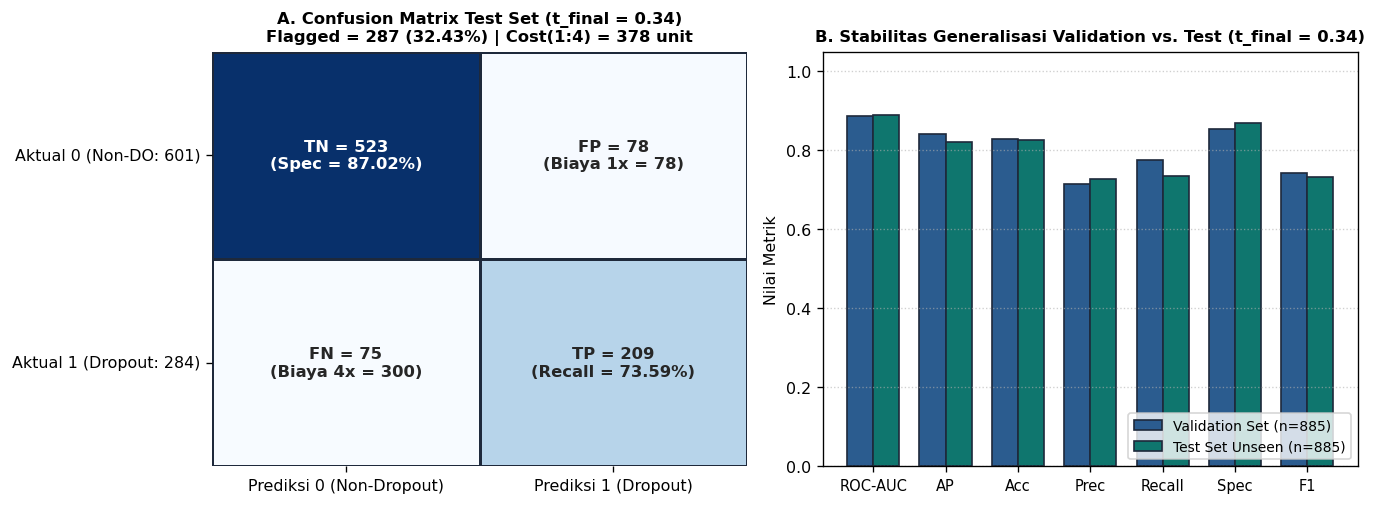

In [14]:
# Bagian 7.2 (Kode): Evaluasi Akhir Satu Kali pada Unseen Test Set (n = 885)
T_FINAL = KONFIGURASI_FINAL_TERKUNCI["threshold_operasional_final"]
C_FP_FINAL = KONFIGURASI_FINAL_TERKUNCI["skenario_biaya_acuan"]["Cost_FP"]
C_FN_FINAL = KONFIGURASI_FINAL_TERKUNCI["skenario_biaya_acuan"]["Cost_FN"]

y_proba_test = model_final_terkunci.predict_proba(X_test_locked)[:, 1]

def ringkasan_evaluasi_lengkap(nama_partisi: str, y_true: np.ndarray, y_prob: np.ndarray, thr: float) -> dict:
    ev = evaluasi_satu_threshold(y_true, y_prob, thr)
    prec_c, rec_c, _ = precision_recall_curve(y_true, y_prob)
    ece_10, _ = hitung_ece_dan_tabel_bin(y_true, y_prob, n_bins=10)
    ev["Partisi & Skema"] = nama_partisi
    ev["ROC_AUC"] = round(roc_auc_score(y_true, y_prob), 4)
    ev["AP"] = round(average_precision_score(y_true, y_prob), 4)
    ev["Trap_PR_AUC"] = round(auc(rec_c, prec_c), 4)
    ev["Brier_Score"] = round(brier_score_loss(y_true, y_prob), 4)
    ev["ECE_10Bin"] = round(ece_10, 4)
    ev["Error_Cost_1_4"] = int(C_FP_FINAL * ev["FP"] + C_FN_FINAL * ev["FN"])
    return ev

hasil_val_final = ringkasan_evaluasi_lengkap(f"Validation Set (t_final = {T_FINAL:.2f})", y_val, y_proba_val, T_FINAL)
hasil_test_final = ringkasan_evaluasi_lengkap(f"Test Set Final (t_final = {T_FINAL:.2f} - Terkunci)", y_test_locked, y_proba_test, T_FINAL)
hasil_test_ref050 = ringkasan_evaluasi_lengkap("Test Set Pembanding Acuan Default (t = 0.50)", y_test_locked, y_proba_test, 0.50)

df_perbandingan_akhir = pd.DataFrame([hasil_val_final, hasil_test_final, hasil_test_ref050])
kolom_akhir = [
    "Partisi & Skema", "Threshold", "TP", "FP", "TN", "FN",
    "Accuracy", "Precision", "Recall", "Specificity", "F1",
    "Flagged", "Flagged_Pct", "Error_Cost_1_4",
    "ROC_AUC", "AP", "Trap_PR_AUC", "Brier_Score", "ECE_10Bin",
]
print("=== HASIL EVALUASI AKHIR PADA UNSEEN TEST SET (n = 885) DIBANDINGKAN VALIDATION SET ===")
display(df_perbandingan_akhir[kolom_akhir])

# Visualisasi Confusion Matrix Test Set pada Threshold Final Terkunci (t_final = 0.34)
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.3))
cm_test_final = np.array([[hasil_test_final["TN"], hasil_test_final["FP"]], [hasil_test_final["FN"], hasil_test_final["TP"]]])
lbl_test_final = np.array([
    [f"TN = {hasil_test_final['TN']}\n(Spec = {hasil_test_final['Specificity']*100:.2f}%)",
     f"FP = {hasil_test_final['FP']}\n(Biaya 1x = {hasil_test_final['FP']})"],
    [f"FN = {hasil_test_final['FN']}\n(Biaya 4x = {4*hasil_test_final['FN']})",
     f"TP = {hasil_test_final['TP']}\n(Recall = {hasil_test_final['Recall']*100:.2f}%)"],
])
sns.heatmap(
    cm_test_final, annot=lbl_test_final, fmt="", cmap="Blues", cbar=False, ax=axes[0],
    linewidths=1.6, linecolor="#1e293b", annot_kws={"fontsize": 9.8, "fontweight": "bold"}
)
axes[0].set_title(
    f"A. Confusion Matrix Test Set (t_final = {T_FINAL:.2f})\n"
    f"Flagged = {hasil_test_final['Flagged']} ({hasil_test_final['Flagged_Pct']:.2f}%) | Cost(1:4) = {hasil_test_final['Error_Cost_1_4']} unit",
    fontweight="bold", fontsize=9.8
)
axes[0].set_xticklabels(["Prediksi 0 (Non-Dropout)", "Prediksi 1 (Dropout)"])
axes[0].set_yticklabels(["Aktual 0 (Non-DO: 601)", "Aktual 1 (Dropout: 284)"], rotation=0)

# Panel B: Perbandingan Bar Metrik Validation vs Test pada t_final = 0.34
nama_metrik_bar = ["ROC_AUC", "AP", "Accuracy", "Precision", "Recall", "Specificity", "F1"]
val_bars = [hasil_val_final[m] for m in nama_metrik_bar]
test_bars = [hasil_test_final[m] for m in nama_metrik_bar]
x_pos = np.arange(len(nama_metrik_bar))
w_bar = 0.36
axes[1].bar(x_pos - w_bar/2, val_bars, width=w_bar, color="#2b5c8f", edgecolor="#1e293b", label="Validation Set (n=885)")
axes[1].bar(x_pos + w_bar/2, test_bars, width=w_bar, color="#0f766e", edgecolor="#1e293b", label="Test Set Unseen (n=885)")
axes[1].set_xticks(x_pos)
axes[1].set_xticklabels(["ROC-AUC", "AP", "Acc", "Prec", "Recall", "Spec", "F1"], fontsize=8.8)
axes[1].set_ylim(0, 1.05)
axes[1].set_ylabel("Nilai Metrik")
axes[1].set_title("B. Stabilitas Generalisasi Validation vs. Test (t_final = 0.34)", fontweight="bold", fontsize=9.8)
axes[1].legend(loc="lower right", fontsize=8.3)
axes[1].grid(axis="y", linestyle=":", alpha=0.6)

plt.tight_layout()
plt.savefig(VIS_DIR / "05_evaluasi_akhir_test_set.png", bbox_inches="tight")
plt.show()


In [15]:
# Bagian 7.3 (Kode): Audit Konsistensi Numerik Otomatis (Programmatic Assertions)
for nama_cek, d_cek, n_ekspektasi, n_pos_ekspektasi in [
    ("Validation t=0.30", hasil_3_threshold[0], 885, 284),
    ("Validation t=0.50", hasil_3_threshold[1], 885, 284),
    ("Validation t=0.70", hasil_3_threshold[2], 885, 284),
    ("Validation t_final=0.34", hasil_val_final, 885, 284),
    ("Test t_final=0.34", hasil_test_final, 885, 284),
]:
    tp, fp, tn, fn = d_cek["TP"], d_cek["FP"], d_cek["TN"], d_cek["FN"]
    assert tp + fp + tn + fn == n_ekspektasi, f"Total sampel salah pada {nama_cek}"
    assert tp + fn == n_pos_ekspektasi, f"Total kelas positif salah pada {nama_cek}"
    assert d_cek["Flagged"] == tp + fp, f"Jumlah Flagged tidak cocok pada {nama_cek}"
    assert d_cek["Pred_Negatif"] == tn + fn, f"Jumlah Pred_Negatif tidak cocok pada {nama_cek}"
    assert np.isclose(d_cek["Precision"], tp / (tp + fp), atol=1e-4), f"Precision tidak cocok pada {nama_cek}"
    assert np.isclose(d_cek["Recall"], tp / (tp + fn), atol=1e-4), f"Recall tidak cocok pada {nama_cek}"
    assert np.isclose(d_cek["Specificity"], tn / (tn + fp), atol=1e-4), f"Specificity tidak cocok pada {nama_cek}"
    f1_manual = 2 * (tp / (tp + fp)) * (tp / (tp + fn)) / ((tp / (tp + fp)) + (tp / (tp + fn)))
    assert np.isclose(d_cek["F1"], f1_manual, atol=1e-4), f"F1 tidak cocok pada {nama_cek}"

assert np.isclose(prevalensi_pos_val, 284 / 885, atol=1e-6), "Baseline PR prevalensi validasi tidak cocok"
assert hasil_val_final["Error_Cost_1_4"] == hasil_val_final["FP"] + 4 * hasil_val_final["FN"]
assert hasil_test_final["Error_Cost_1_4"] == hasil_test_final["FP"] + 4 * hasil_test_final["FN"]
assert KONFIGURASI_FINAL_TERKUNCI["threshold_operasional_final"] == 0.34

print("AUDIT KONSISTENSI NUMERIK LULUS 100%: Seluruh identitas Confusion Matrix, metrik, prevalensi, dan biaya telah terverifikasi otomatis.")


AUDIT KONSISTENSI NUMERIK LULUS 100%: Seluruh identitas Confusion Matrix, metrik, prevalensi, dan biaya telah terverifikasi otomatis.


#### Interpretasi Hasil Evaluasi Akhir pada *Test Set* ($n = 885$)
1. **Stabilitas Daya Pisah dan Kalibrasi pada Data Baru:**  
   Pada *Test Set* yang belum pernah tersentuh sebelumnya, model menghasilkan **`ROC-AUC = 0,8898`** (sangat konsisten dibanding *Validation* `0,8868`), **`Brier Score = 0,1184`** (vs. `0,1136` di *Validation*), dan **`ECE (10-Bin) = 0,0234`** (bahkan sedikit lebih rapat daripada `0,0270` di *Validation*). Sementara itu, nilai **`Average Precision (AP)`** mengalami penurunan ringan yang wajar dari **`0,8408` menjadi `0,8217`** (`-0,0191`), yang dilaporkan secara jujur tanpa penyesuaian ulang model.
2. **Kinerja Operasional pada *Threshold* Terkunci (`t_final = 0,34`):**  
   * **Kepatuhan Kapasitas:** Pada *Test Set*, `t_final = 0,34` menandai **`287` dari `885` mahasiswa (`32,43%` kohort)**—tetap aman berada di bawah batas simulasi kapasitas `<= 35%`!
   * **Keseimbangan Metrik:** *Precision* tercatat sedikit meningkat menjadi **`72,82%`** (vs. `71,43%` di *Validation*) dan *Specificity* naik menjadi **`87,02%`** (vs. `85,36%`), sementara *Recall* mengalami sedikit penurunan generalisasi dari **`77,46%` ke `73,59%`** (`TP = 209`, `FN = 75`, `F1 = 0,7320`).
   * **Efisiensi Biaya Kesalahan (`1:4`):** *Threshold* operasional `t_final = 0,34` menghasilkan **`Total Error Cost = 378 satuan`** pada *Test Set*, menghemat **`75 satuan biaya` (`-16,56%`)** dan mendeteksi **`27` mahasiswa *dropout* lebih banyak** (`209` vs. `182`) dibandingkan jika menggunakan ambang bawaan `t = 0,50` (`453 satuan`, `FN = 102`, `Recall = 64,08%`).


---
## BAGIAN 8 — Proposal Penelitian Artikel UAS dan Bukti Verifikasi Jurnal SINTA 4

### 8.1 Proposal Penelitian Ringkas Berbasis Eksperimen Aktual (22 Komponen Lengkap)

1. **Judul Penelitian:**  
   *Optimasi Ambang Keputusan Sensitif Biaya dan Kalibrasi Probabilitas pada Model Regresi Logistik untuk Prediksi Risiko Putus Studi Mahasiswa Pasca-Semester Pertama*
2. **Latar Belakang:**  
   Tingginya angka putus studi (*dropout*) pada pendidikan tinggi menuntut sistem peringatan dini berbasis data akademik awal. Namun, banyak studi klasifikasi *dropout* hanya berhenti pada pelaporan akurasi atau `ROC-AUC` pada ambang bawaan `0,50`, menggunakan fitur semester akhir yang memicu *temporal data leakage*, serta belum mengevaluasi apakah probabilitas model sudah terkalibrasi ketika dikaitkan dengan asimetri biaya kesalahan dan keterbatasan kuota konseling akademik.
3. **Rumusan Masalah:**  
   Pada dataset pendidikan tinggi dengan proporsi *dropout* sekitar sepertiga kohort (`32,12%`) dan titik keputusan yang dibatasi secara ketat pada akhir Semester Pertama, penggunaan ambang keputusan `0,50` maupun pemberian bobot `class_weight='balanced'` tanpa kalibrasi berisiko menghasilkan tingkat *False Negative* yang mahal atau distorsi estimasi peluang risiko.
4. **Pertanyaan Penelitian (*Research Questions*):**  
   * **RQ1:** Bagaimana kinerja diskriminasi (`ROC-AUC`, *Average Precision*, dan *Trapezoidal PR-AUC*) model Regresi Logistik dibandingkan *baseline* `DummyClassifier` dan model pembanding `DecisionTreeClassifier` dalam mengklasifikasikan risiko *dropout* menggunakan 28 fitur bebas kebocoran pada akhir Semester Pertama?
   * **RQ2:** Bagaimana pengaruh kalibrasi probabilitas eksplisit (*Platt/Sigmoid Scaling* dan *Isotonic Regression*) dibandingkan probabilitas bawaan dan `class_weight='balanced'` terhadap *Brier Score* dan *Expected Calibration Error* (ECE)?
   * **RQ3:** Bagaimana perubahan ambang keputusan (*threshold*) memengaruhi *Precision*, *Recall*, *Specificity*, *F1-Score*, total biaya kesalahan pada berbagai rasio penalti ($1:1$ hingga $1:8$), serta kepatuhan terhadap batas simulasi kapasitas tindak lanjut?
5. **Tujuan Penelitian:**  
   Mengukur kinerja pemisahan dan kalibrasi probabilitas model Regresi Logistik pasca-Semester Pertama secara bebas kebocoran data, serta merumuskan prosedur pemilihan *threshold* operasional yang meminimalkan biaya kesalahan asimetris di bawah kendala kapasitas layanan pembinaan akademik.
6. **Dataset:**  
   *Predict Students' Dropout and Academic Success* ($N = 4.424$ observasi mahasiswa lintas 17 program studi sarjana, 36 atribut prediktor + 1 label `Target`), dikumpulkan pada *Instituto Politécnico de Portalegre*, Portugal (tahun akademik 2008/2009–2018/2019).
7. **Sumber Dataset & Lisensi:**  
   UCI Machine Learning Repository ID #697 (Realinho et al., 2022; DOI: `10.24432/C5TG7T`, Lisensi terbuka `CC BY 4.0`).
8. **Unit Analisis:**  
   Satu individu mahasiswa program sarjana per baris observasi.
9. **Definisi Target:**  
   Klasifikasi biner dengan kelas positif `Dropout = 1` (`1.421` mahasiswa; `32,12%`) dan kelas negatif `Non-Dropout = 0` (`3.003` mahasiswa; `67,88%` gabungan `Graduate = 2.209` dan `Enrolled = 794`).
10. **Waktu Prediksi & Pengendalian Leakage:**  
    Tepat setelah evaluasi akademik Semester Pertama berakhir (Skenario B Konservatif). Enam fitur akademik Semester Kedua dan dua variabel status keuangan tanpa stempel waktu per semester (`Debtor`, `Tuition fees up to date`) dikeluarkan sehingga tersisa **28 fitur sah**.
11. **Baseline:**  
    `DummyClassifier(strategy='prior')` (`ROC-AUC = 0,5000`, `AP Val = 0,3209`) dan `DummyClassifier(strategy='stratified')`, serta evaluasi model utama pada ambang baku `t = 0,50`.
12. **Model Utama:**  
    Pipeline `LogisticRegression(C=1.0)` yang dikalibrasi secara eksplisit menggunakan `CalibratedClassifierCV(method='isotonic', cv=5)` pada *Training Set*.
13. **Model Pembanding:**  
    `LogisticRegression` (*Native*), `LogisticRegression(class_weight='balanced')`, `LogisticRegression + Platt/Sigmoid Calibration`, serta `DecisionTreeClassifier` (*Unpruned* vs. *Pruned* `max_depth=5, min_samples_leaf=20` beserta versi terkalibrasinya).
14. **Preprocessing:**  
    `ColumnTransformer` di dalam `Pipeline`: 13 fitur numerik (`SimpleImputer(median)` + `StandardScaler`), 6 fitur biner (`SimpleImputer(most_frequent)`), dan 9 fitur kategorikal nominal berkode integer (`SimpleImputer(most_frequent)` + `OneHotEncoder(handle_unknown='ignore')`).
15. **Pembagian Data:**  
    *Stratified split* tiga arah dengan `SEED = 42`: *Training Set* `60%` ($n = 2.654$), *Validation Set* `20%` ($n = 885$), dan *Unseen Test Set* `20%` ($n = 885$).
16. **Metrik Evaluasi Diskriminasi & Klasifikasi:**  
    `ROC-AUC`, `Average Precision (AP)`, `Trapezoidal PR-AUC`, serta `Accuracy`, `Precision`, `Recall`, `Specificity`, `F1-Score`, `FPR`, `FNR`, dan proporsi mahasiswa tertandai (*Flagged*).
17. **Evaluasi Kalibrasi:**  
    `Brier Score Loss`, `Expected Calibration Error (ECE)` 10-*bin* & 5-*bin* seragam, serta kurva *Reliability Diagram*.
18. **Metode Penentuan Threshold:**  
    Pencarian sistematis pada *Validation Set* (grid `0,05–0,95` langkah `0,01` dan seluruh titik probabilitas unik) yang menggabungkan minimisasi biaya kesalahan dengan kendala batas persentase kapasitas tindak lanjut, lalu dikunci (`t_final = 0,34`) sebelum evaluasi tunggal di *Test Set*.
19. **Matriks Biaya:**  
    Biaya kesalahan ternormalisasi ($C_{\text{FP}} = 1$ satuan) dengan uji sensitivitas empat rasio $C_{\text{FP}} : C_{\text{FN}} \in \{1:1, 1:2, 1:4, 1:8\}$ dan skenario acuan $1:4$.
20. **Rencana Tahapan Eksperimen Menuju Naskah Final UAS:**  
    * *Tahap 1 (Pertemuan 11 — Selesai):* Audit dataset & kebocoran temporal, implementasi pipeline, eksperimen kalibrasi, sensitivitas biaya & kapasitas, serta penguncian evaluasi *Test Set*.
    * *Tahap 2 (Pertemuan 12–13):* Analisis koefisien fitur dan *permutation importance* pada model terkalibrasi serta pembandingan tambahan dengan ansambel pohon (*Random Forest* / *Gradient Boosting*) menggunakan skema partisi yang sama.
    * *Tahap 3 (Pertemuan 14–15):* Penyusunan naskah lengkap berformat IMRaD (8–12 halaman, gaya sitasi IEEE) sesuai templat jurnal target SINTA 4 dan pemeriksaan kemiripan naskah.
21. **Kontribusi Penelitian yang Realistis:**  
    * *Kontribusi Metodologis:* Mendokumentasikan audit kebocoran temporal secara eksplisit pada dataset UCI #697 (termasuk pengujian risiko bias variabel administrasi keuangan tanpa stempel waktu semester).
    * *Kontribusi Evaluasi:* Membuktikan secara empiris perbedaan distorsi kalibrasi antara `class_weight='balanced'` dan kalibrasi isotonik/Platt serta perbedaan *Average Precision* terhadap *Trapezoidal PR-AUC* pada model bertingkat.
    * *Kontribusi Praktis:* Menyediakan kerangka simulasi penentuan *threshold* yang menyelaraskan rasio biaya kesalahan dengan kuota kapasitas layanan bimbingan akademik.
22. **Keterbatasan Penelitian:**  
    Data berasal dari satu institusi di Portugal sehingga tidak dapat digeneralisasikan langsung ke perguruan tinggi Indonesia; penyatuan label `Enrolled` ke `Non-Dropout` mengandung sensor kanan (*right-censoring*); serta rasio biaya dan persentase kapasitas merupakan skenario simulasi kebijakan, bukan data akuntansi empiris institusi.

---

### 8.2 Verifikasi Resmi Calon Jurnal Ilmiah Target SINTA 4
Verifikasi dilakukan pada **26 November 2026** melalui portal resmi SINTA Kemdiktisaintek dan laman *Open Journal Systems* (OJS) masing-masing jurnal (berkas dokumentasi dan tangkapan layar laman OJS tersimpan pada folder `bukti_sinta/`).


In [16]:
# Bagian 8.2 (Kode): Tabel Verifikasi Calon Jurnal SINTA 4 & Pemeriksaan Keberadaan Bukti Lokal
df_verifikasi_jurnal = pd.DataFrame([
    {
        "Jurnal": "KOMPUTA : Jurnal Ilmiah Komputer dan Informatika (UNIKOM) [Kandidat Utama 1]",
        "SINTA ID": "1324",
        "Peringkat": "SINTA 4",
        "Masa berlaku": "Mulai Vol. 12 No. 1 Tahun 2023 (berlaku 5 tahun s.d. 2027/2028; p-ISSN 2089-9033, e-ISSN 2715-7849)",
        "Scope relevan": "Kecerdasan Buatan (AI), Pembelajaran Mesin, Ilmu Komputer, dan Sistem Informasi (8-12 hal., sitasi IEEE)",
        "URL SINTA": "https://sinta.kemdiktisaintek.go.id/journals/profile/1324",
        "URL OJS": "https://ojs.unikom.ac.id/index.php/komputa",
    },
    {
        "Jurnal": "Infotek : Jurnal Informatika dan Teknologi (Univ. Hamzanwadi) [Kandidat Utama 2]",
        "SINTA ID": "6347",
        "Peringkat": "SINTA 4",
        "Masa berlaku": "SK No. 225/E/KPT/2022 mulai Vol. 5 No. 2 Tahun 2022 (5 tahun s.d. 2027; e-ISSN 2614-8773, DOI 10.29408)",
        "Scope relevan": "Keilmuan Informatika, Data Mining, dan E-Learning (terbit Januari & Juli, cocok untuk Educational Data Mining)",
        "URL SINTA": "https://sinta.kemdiktisaintek.go.id/journals/profile/6347",
        "URL OJS": "https://e-journal.hamzanwadi.ac.id/index.php/infotek",
    },
    {
        "Jurnal": "JIKO (Jurnal Informatika dan Komputer) — UTDI Yogyakarta [Kandidat Cadangan]",
        "SINTA ID": "103",
        "Peringkat": "SINTA 4",
        "Masa berlaku": "SK No. 79/E/KPT/2023 berlaku sejak Sept 2022 s.d. 2027 (p-ISSN 2477-4413, e-ISSN 2477-3964)",
        "Scope relevan": "Ilmu Komputer & Informatika: Machine Learning, Klasifikasi, dan Sistem Pendukung Keputusan (5.000-8.500 kata, IEEE)",
        "URL SINTA": "https://sinta.kemdiktisaintek.go.id/journals/profile/103",
        "URL OJS": "https://ejournal.utdi.ac.id/index.php/jiko",
    },
])

print("=== TABEL VERIFIKASI TERBARU CALON JURNAL TARGET SINTA 4 (PER 26 NOVEMBER 2026) ===")
display(df_verifikasi_jurnal)

folder_bukti = Path("bukti_sinta")
if folder_bukti.is_dir():
    daftar_bukti = sorted([p.name for p in folder_bukti.iterdir()])
    print(f"Berkas bukti verifikasi pada folder '{folder_bukti}/': {daftar_bukti}")


=== TABEL VERIFIKASI TERBARU CALON JURNAL TARGET SINTA 4 (PER 26 NOVEMBER 2026) ===


,Jurnal,SINTA ID,Peringkat,Masa berlaku,Scope relevan,URL SINTA,URL OJS
0,KOMPUTA : Jurnal Ilmiah Komputer dan Informatika (UNIKOM) [Kandidat Utama 1],1324,SINTA 4,"Mulai Vol. 12 No. 1 Tahun 2023 (berlaku 5 tahun s.d. 2027/2028; p-ISSN 2089-9033, e-ISSN 2715-7849)","Kecerdasan Buatan (AI), Pembelajaran Mesin, Ilmu Komputer, dan Sistem Informasi (8-12 hal., sitasi IEEE)",https://sinta.kemdiktisaintek.go.id/journals/profile/1324,https://ojs.unikom.ac.id/index.php/komputa
1,Infotek : Jurnal Informatika dan Teknologi (Univ. Hamzanwadi) [Kandidat Utama 2],6347,SINTA 4,"SK No. 225/E/KPT/2022 mulai Vol. 5 No. 2 Tahun 2022 (5 tahun s.d. 2027; e-ISSN 2614-8773, DOI 10.29408)","Keilmuan Informatika, Data Mining, dan E-Learning (terbit Januari & Juli, cocok untuk Educational Data Mining)",https://sinta.kemdiktisaintek.go.id/journals/profile/6347,https://e-journal.hamzanwadi.ac.id/index.php/infotek
2,JIKO (Jurnal Informatika dan Komputer) — UTDI Yogyakarta [Kandidat Cadangan],103,SINTA 4,"SK No. 79/E/KPT/2023 berlaku sejak Sept 2022 s.d. 2027 (p-ISSN 2477-4413, e-ISSN 2477-3964)","Ilmu Komputer & Informatika: Machine Learning, Klasifikasi, dan Sistem Pendukung Keputusan (5.000-8.500 kata, IEEE)",https://sinta.kemdiktisaintek.go.id/journals/profile/103,https://ejournal.utdi.ac.id/index.php/jiko


Berkas bukti verifikasi pada folder 'bukti_sinta/': ['VERIFIKASI_JURNAL_SINTA4.md', 'infotek_ojs_resmi.png', 'komputa_ojs_resmi.png']


*Alasan Pemilihan Dua Kandidat Utama Berdasarkan Scope:* **KOMPUTA (UNIKOM)** dan **Infotek (Universitas Hamzanwadi)** dipilih sebagai dua kandidat paling relevan karena keduanya secara eksplisit mencakup bidang *Pembelajaran Mesin / Kecerdasan Buatan* serta *Data Mining & E-Learning*, memiliki format naskah ringkas yang sesuai dengan ruang lingkup studi eksperimen dataset publik teraudit, serta laman OJS keduanya dapat diakses dan diverifikasi secara langsung (termasuk pengumuman penerimaan naskah *Infotek Vol. 10 No. 1 Januari 2027*). **JIKO (UTDI)** dipertahankan sebagai opsi ketiga dengan cakupan *Machine Learning* dan Sistem Pendukung Keputusan. *(Catatan: Penetapan jurnal target ini merupakan perencanaan akademik, bukan jaminan penerimaan naskah).*


---
## BAGIAN 9 — Jawaban Lima Latihan Analitis, Kesimpulan, Keterbatasan, dan Daftar Pustaka

### 9.1 Jawaban Lima Latihan Analitis Wajib Dosen

#### 1. Kapan *Recall* perlu diprioritaskan?
*Recall* ($\frac{\text{TP}}{\text{TP} + \text{FN}}$) perlu diprioritaskan ketika **kerugian atau bahaya akibat gagal mendeteksi satu kejadian positif (*False Negative* / FN) jauh lebih berat dibandingkan biaya memeriksa satu prediksi positif yang keliru (*False Positive* / FP)**. Dalam konteks pendidikan tinggi, melewatkan seorang mahasiswa yang benar-benar berisiko putus studi (`FN`) membuat mahasiswa tersebut tidak memperoleh pendampingan dini sebelum terlambat, sedangkan satu panggilan `FP` hanya memerlukan sesi konsultasi akademik singkat. Prinsip serupa berlaku pada penapisan awal penyakit serius di bidang medis dan deteksi transaksi penipuan (*fraud*).

#### 2. Hitung *Precision* apabila $\text{TP} = 40$ dan $\text{FP} = 10$.
Perhitungan menggunakan definisi *Precision*:
$$\text{Precision} = \frac{\text{TP}}{\text{TP} + \text{FP}}$$
$$= \frac{40}{40 + 10}$$
$$= \frac{40}{50}$$
$$= 0{,}80 \text{ atau } 80\%$$
**Makna praktis:** Dari total `50` individu yang diprediksi positif oleh model (`40 TP + 10 FP`), sebanyak `40` individu (`80%`) benar-benar merupakan kasus positif aktual, sedangkan `10` individu (`20%`) merupakan alarm palsu.

#### 3. Mengapa *Specificity* tetap penting walaupun kita memprioritaskan *Recall*?
*Specificity* ($\frac{\text{TN}}{\text{TN} + \text{FP}}$) mengukur kemampuan model mengenali kelas negatif (mahasiswa yang bertahan/lulus) dengan benar. Apabila kita hanya mengejar *Recall* setinggi mungkin tanpa memedulikan *Specificity*—misalnya menurunkan *threshold* mendekati `0,00` hingga semua mahasiswa diprediksi berisiko—maka *Recall* memang mencapai `100%`, tetapi *Specificity* jatuh menjadi `0%`. Dampaknya: (1) kuota konseling dosen pembimbing langsung kewalahan oleh ratusan mahasiswa yang sebenarnya tidak bermasalah, (2) biaya operasional `FP` membengkak drastis terutama ketika kelas negatif berjumlah mayoritas (`67,88%` pada dataset ini), dan (3) tingkat kepercayaan pengguna terhadap sistem menurun akibat terlalu banyak alarm palsu (*alarm fatigue*).

#### 4. Apa *baseline* dari metrik PR-AUC?
Berbeda dari `ROC-AUC` yang memiliki *baseline* teoretis tetap `0,50` pada distribusi kelas apa pun, **baseline teoretis dari kurva Precision–Recall (PR-AUC) adalah nilai prevalensi (proporsi) kelas positif di dalam data yang dievaluasi**:
$$\text{Baseline PR-AUC} = \frac{P}{P + N}$$
Model tanpa kemampuan pemisahan (*no-skill classifier*) yang menebak secara acak atau memberi skor konstan akan memperoleh tingkat *Precision* rata-rata sebesar proporsi kelas positif $\frac{P}{P+N}$ di sepanjang nilai *Recall*, membentuk garis mendatar pada ketinggian prevalensi tersebut (pada *Validation Set* kita bernilai $\frac{284}{885} = 0{,}3209$). Perlu dibedakan antara **baseline teoretis** ini (`0,3209`) dengan capaian **Average Precision (AP)** model aktual (`0,8408` di *Validation* dan `0,8217` di *Test*), serta perlu dicatat bahwa perhitungan *Trapezoidal PR-AUC* pada model berskor konstan dapat tampak lebih tinggi secara semu (`0,6605`) akibat interpolasi garis lurus trapesium.

#### 5. Jelaskan perbedaan antara *Diskriminasi* dan *Kalibrasi*!
* **Diskriminasi (*Discrimination*):** Mengukur seberapa baik model **memisahkan dan mengurutkan peringkat skor** antara kelas positif dan kelas negatif (apakah kasus `Dropout` konsisten diberi skor lebih tinggi daripada `Non-Dropout`). Diskriminasi hanya bergantung pada urutan peringkat relatif skor dan diukur dengan `ROC-AUC` serta `AP`. Model yang seluruh skornya dikali dua atau digeser naik tetap memiliki nilai `ROC-AUC` yang persis sama.
* **Kalibrasi (*Calibration*):** Mengukur seberapa akurat **nilai numerik probabilitas $\hat{p}$** mencerminkan frekuensi kejadian aktual di lapangan. Jika sebuah model terkalibrasi dengan baik memberi probabilitas `0,30` kepada seratus mahasiswa, maka sekitar `30` orang di antaranya benar-benar mengalami `Dropout`. Kalibrasi diukur dengan *Brier Score*, *Expected Calibration Error* (ECE), dan *Reliability Diagram*. Pada eksperimen kita, `LogReg (Balanced)` memiliki diskriminasi tinggi (`ROC-AUC = 0,8844`) tetapi kalibrasinya buruk (`ECE = 0,0975`), sedangkan `LogReg + Isotonic` unggul pada diskriminasi (`ROC-AUC = 0,8868`) **sekaligus** terkalibrasi dengan baik (`ECE = 0,0270`).

---

### 9.2 Kesimpulan

1. **Pencegahan Kebocoran Temporal dan Kinerja Pemisahan Model:**  
   Audit terhadap `dataset-asli.csv` (UCI #697; $N = 4.424$ mahasiswa; `32,12% Dropout`) menunjukkan perlunya mengeluarkan 6 fitur akademik Semester Kedua serta 2 atribut keuangan tanpa stempel waktu semester (`Debtor` dan `Tuition fees up to date`) untuk menjaga validitas prediksi akhir Semester Pertama (28 fitur). Pada *Validation Set* ($n = 885$), model utama **`LogReg + Isotonic (CV=5)`** menghasilkan **`ROC-AUC = 0,8868`** dan **`Average Precision (AP) = 0,8408`** (melampaui *baseline* prevalensi `0,3209` serta pohon keputusan terpangkas `ROC-AUC = 0,8499`, `AP = 0,7765`).
2. **Pentingnya Kalibrasi Probabilitas Eksplisit:**  
   Penggunaan `class_weight='balanced'` tanpa kalibrasi terbukti mendistorsi estimasi peluang (`Brier Score Val = 0,1306`, `ECE 10-Bin = 0,0975`). Penerapan `CalibratedClassifierCV` dengan regresi isotonik pada *Training Set* menurunkan galat kalibrasi hingga **`Brier Score = 0,1136`** dan **`ECE 10-Bin = 0,0270`**, sehingga skor probabilitas layak dijadikan dasar perhitungan ambang berbasis biaya.
3. **Keputusan Threshold Berbasis Biaya dan Kapasitas serta Generalisasi *Test Set*:**  
   Evaluasi tiga ambang wajib di *Validation Set* menunjukkan bahwa `t = 0,50` melewatkan `87` mahasiswa *dropout* (`Recall = 69,37%`, `Biaya 1:4 = 394 satuan`) dan `t = 0,70` melewatkan `136` mahasiswa (`Recall = 52,11%`, `Biaya = 554 satuan`), sementara biaya minimum tanpa batas kuota tercapai di `t = 0,26` (`313 satuan`, namun menandai `42,03%` kohort). Dengan memperhitungkan simulasi batas kapasitas moderat `<= 35%` kohort, ambang operasional dikunci pada **`t_final = 0,34`** (`Flagged Val = 34,80%`, `Biaya Val = 344 satuan`). Saat diuji satu kali pada **Unseen Test Set ($n = 885$)**, konfigurasi terkunci ini mempertahankan generalisasi yang solid (**`ROC-AUC = 0,8898`**, **`AP = 0,8217`**, **`Brier = 0,1184`**, **`ECE = 0,0234`**, **`Precision = 72,82%`**, **`Recall = 73,59%`**, **`Specificity = 87,02%`**, **`F1 = 0,7320`**), menandai `32,43%` kohort, serta memangkas biaya kesalahan sebesar **`75 satuan` (`-16,56%`)** dibandingkan ambang bawaan `0,50`.

---

### 9.3 Keterbatasan Penelitian dan Pencatatan Integritas Akademik

* **Keterbatasan Penelitian:**
  1. *Konteks Populasi:* Data berasal dari perguruan tinggi di Portugal sehingga struktur kurikulum, skala nilai, dan faktor ekonomi makro tidak dapat digeneralisasikan langsung ke perguruan tinggi di Indonesia.
  2. *Penggabungan Kelas `Enrolled`:* Sebanyak `50` dari `88` kasus *False Positive* pada `t_final = 0,34` di *Validation Set* (`56,8%`, padahal proporsi `Enrolled` di dalam populasi `Non-Dropout` hanya `159/601 = 26,5%`) berasal dari mahasiswa berstatus asli `Enrolled` (belum lulus saat akhir pengamatan), yang mengindikasikan adanya fenomena keterlambatan studi dan *right-censoring*.
  3. *Skenario Biaya & Kapasitas:* Rasio biaya ($1:1$ s.d. $1:8$) dan batas kapasitas (`25%` s.d. `40%`) merupakan pemodelan skenario kebijakan, sehingga implementasi nyata memerlukan kalibrasi anggaran dan beban kerja riil pada institusi pengguna.
* **Pencatatan Penggunaan Asisten AI & Tanggung Jawab Ilmiah:**  
  Asisten AI digunakan untuk membantu proses audit kode terdahulu, penyusunan struktur modular pipeline Scikit-learn, perapian visualisasi evaluasi, serta penelusuran metadata jurnal SINTA 4. Seluruh kode telah dieksekusi ulang dari awal secara bersih pada `dataset-asli.csv`, setiap angka diverifikasi menggunakan pemeriksaan otomatis `assert`, dan tanggung jawab penuh atas metodologi serta interpretasi berada pada mahasiswa penulis.

---

### 9.4 Daftar Pustaka

1. Realinho, V., Machado, J., Baptista, L., & Martins, M. V. (2022). Predicting Student Dropout and Academic Success. *Data*, 7(11), 146. https://doi.org/10.3390/data7110146
2. Realinho, V., Machado, J., Baptista, L., & Martins, M. V. (2021). *Predict Students' Dropout and Academic Success* [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C5TG7T
3. Saito, T., & Rehmsmeier, M. (2015). The Precision-Recall Plot Is More Informative than the ROC Plot When Evaluating Binary Classifiers on Imbalanced Datasets. *PLOS ONE*, 10(3), e0118432. https://doi.org/10.1371/journal.pone.0118432
4. Elkan, C. (2001). The Foundations of Cost-Sensitive Learning. *Proceedings of the Seventeenth International Joint Conference on Artificial Intelligence (IJCAI'01)*, 973–978.
5. Niculescu-Mizil, A., & Caruana, R. (2005). Predicting Good Probabilities With Supervised Learning. *Proceedings of the 22nd International Conference on Machine Learning (ICML)*, 625–632. https://doi.org/10.1145/1102351.1102430
6. Pedregosa, F., Varoquaux, G., Gramfort, A., Michel, V., Thirion, B., Grisel, O., ... & Duchesnay, E. (2011). Scikit-learn: Machine Learning in Python. *Journal of Machine Learning Research*, 12, 2825–2830. Dokumentasi resmi *Probability Calibration*: https://scikit-learn.org/stable/modules/calibration.html
